In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline
plt.rcParams['figure.dpi'] = 300

# Training Data

In [ ]:
df_input = pd.read_csv('Data/Key_Training_Data.csv')
df_input = df_input.set_index('id')
print (df_input.shape)
df_input = df_input.sample(frac = 1, random_state = 42)
print (df_input.shape)

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_input.iloc[:,:-1], df_input.iloc[:,[-1]], test_size=0.3, random_state=42)


In [7]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import fbeta_score
from sklearn.metrics import log_loss
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix

# Figure 2

In [8]:
import pickle

# Naive Bayes Classifier
with open('Data/nb_classifier.pkl', 'rb') as f:
    nb_model = pickle.load(f)
    
# Logistic Regression Classifier
with open('Data/lr_classifier.pkl', 'rb') as f:
    lr_model = pickle.load(f)
    
# Random Forest
with open('Data/rf_classifier.pkl', 'rb') as f:
    rf_best_model = pickle.load(f)
    
# Gradient Boosting Classifier
with open('Data/gbc_classifier.pkl', 'rb') as f:
    gbc_best_model = pickle.load(f)
    
# XGBoost
with open('Data/xgb_classifier.pkl', 'rb') as f:
    xgb_best_model = pickle.load(f)

/opt/anaconda3/lib/python3.8/site-packages/xgboost/compat.py:31: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


In [9]:
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5)
X = df_input.iloc[:,:-1].values
y = df_input.iloc[:,[-1]].values

aucs = []

for train_idx, test_idx in cv.split(X, y):    
    y_scores = xgb_best_model.predict_proba(X[test_idx])[:, 1]
    fpr, tpr, _ = roc_curve(y[test_idx], y_scores)
    auc_score = auc(fpr, tpr)
    aucs.append(auc_score)

print(f"Mean AUC: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

Mean AUC: 0.973 ± 0.001


/opt/anaconda3/lib/python3.8/site-packages/xgboost/data.py:192: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


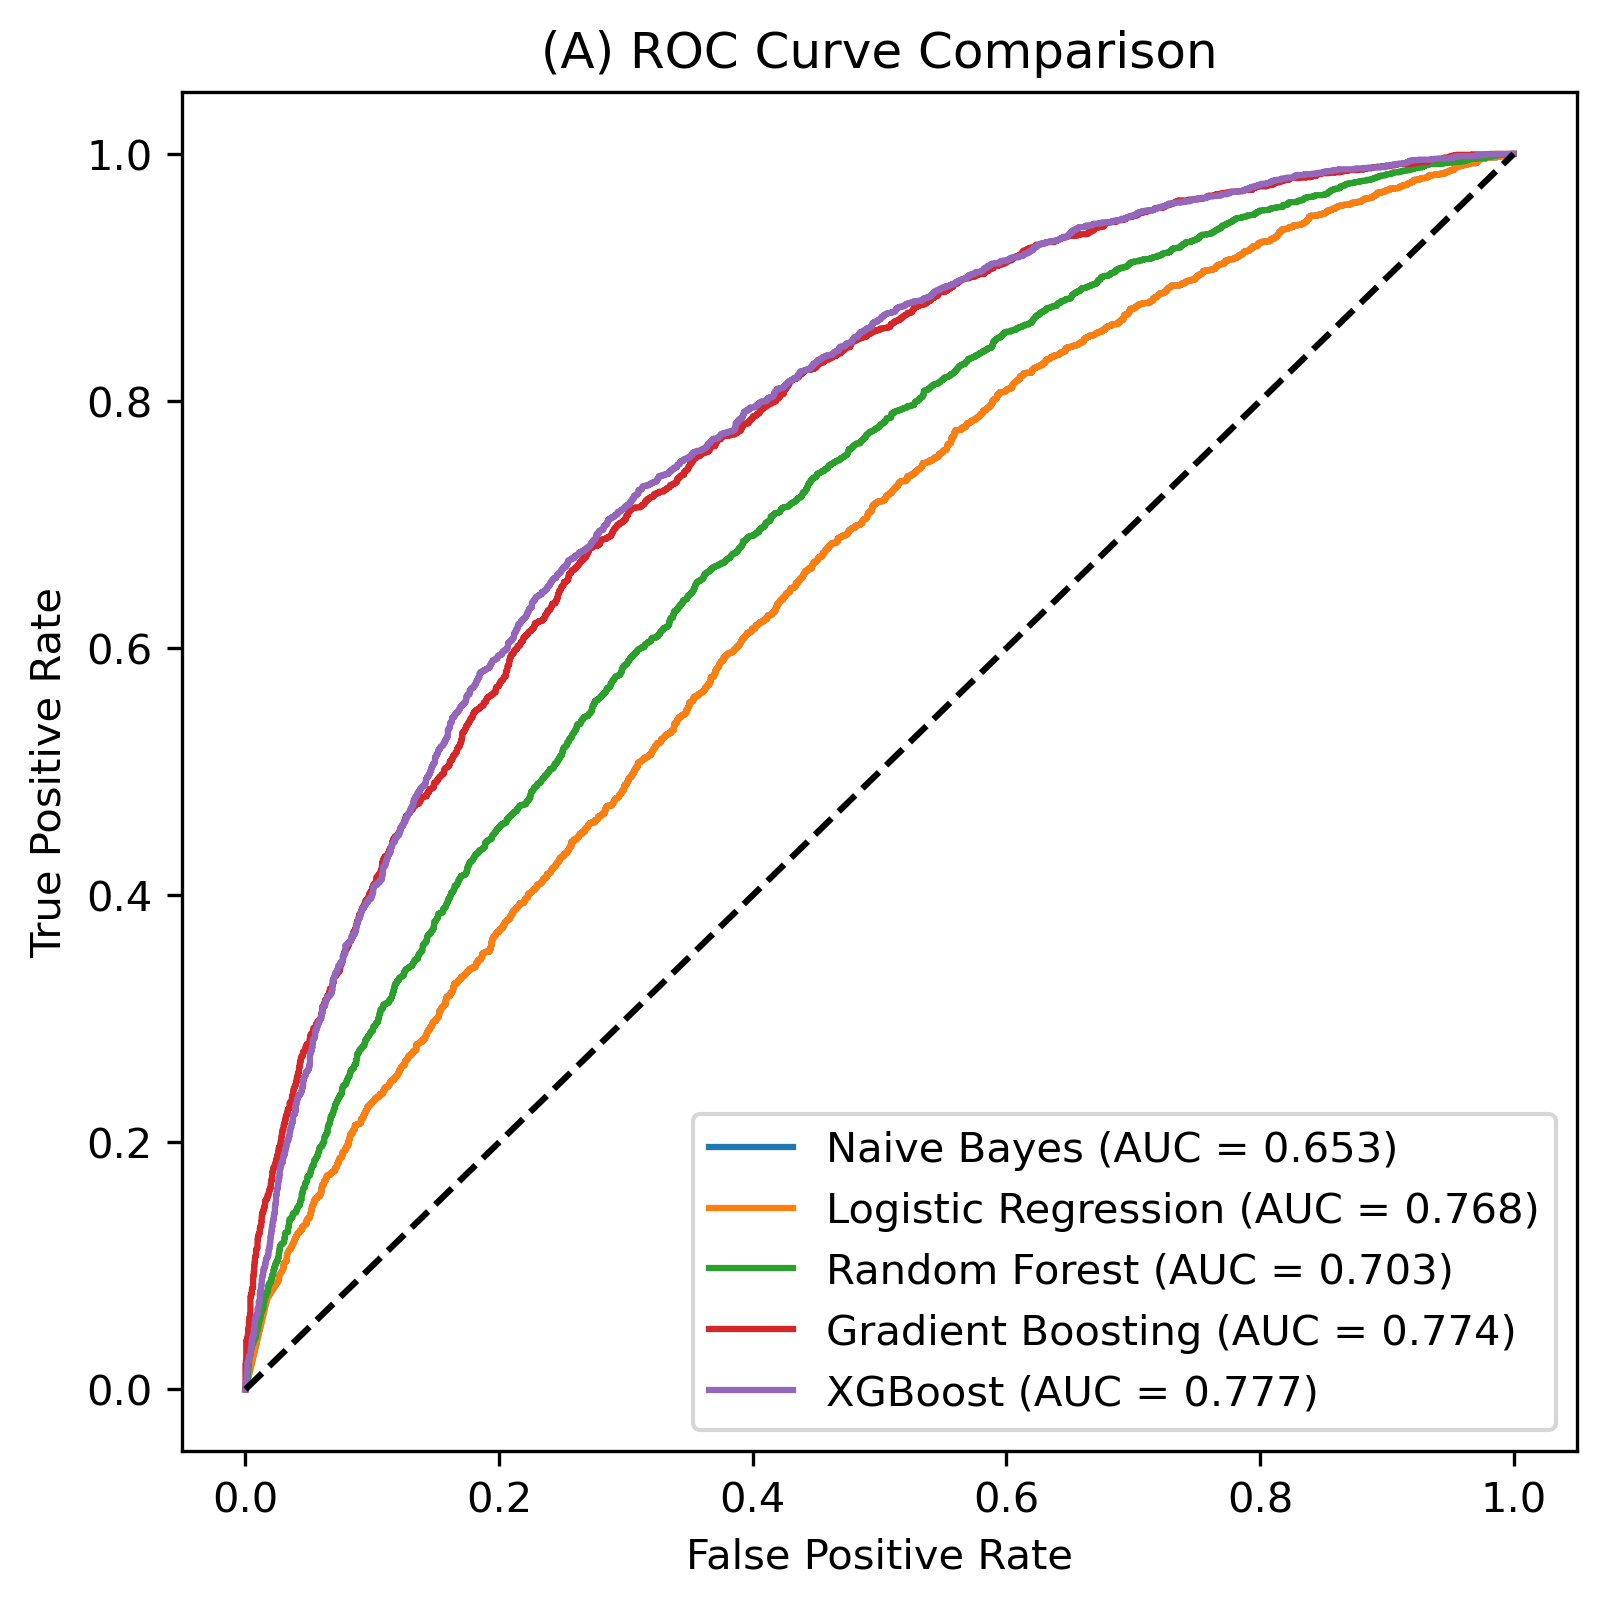

In [10]:


# Get scores
y_scores_nb = nb_model.predict_proba(X_test)[:, 1]
y_scores_lr = lr_model.predict_proba(X_test)[:, 1]
y_scores_rf = rf_best_model.predict_proba(X_test)[:, 1]
y_scores_gbc = gbc_best_model.predict_proba(X_test)[:, 1]
y_scores_xgb = xgb_best_model.predict_proba(X_test)[:, 1]

# ROC for Models
fpr_nb, tpr_nb, _nb = roc_curve(y_test, y_scores_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)

fpr_lr, tpr_lr, _lr = roc_curve(y_test, y_scores_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_rf, tpr_rf, _rf = roc_curve(y_test, y_scores_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_gbc, tpr_gbc, _gbc = roc_curve(y_test, y_scores_gbc)
roc_auc_gbc = auc(fpr_gbc, tpr_gbc)

fpr_xgb, tpr_xgb, _xgb = roc_curve(y_test, y_scores_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot comparison
plt.figure(figsize=(6, 6))

plt.plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {roc_auc_nb:.3f})')
plt.plot(fpr_nb, tpr_nb, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
plt.plot(fpr_gbc, tpr_gbc, label=f'Gradient Boosting (AUC = {roc_auc_gbc:.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('(A) ROC Curve Comparison')
plt.legend(loc='lower right')

plt.show()

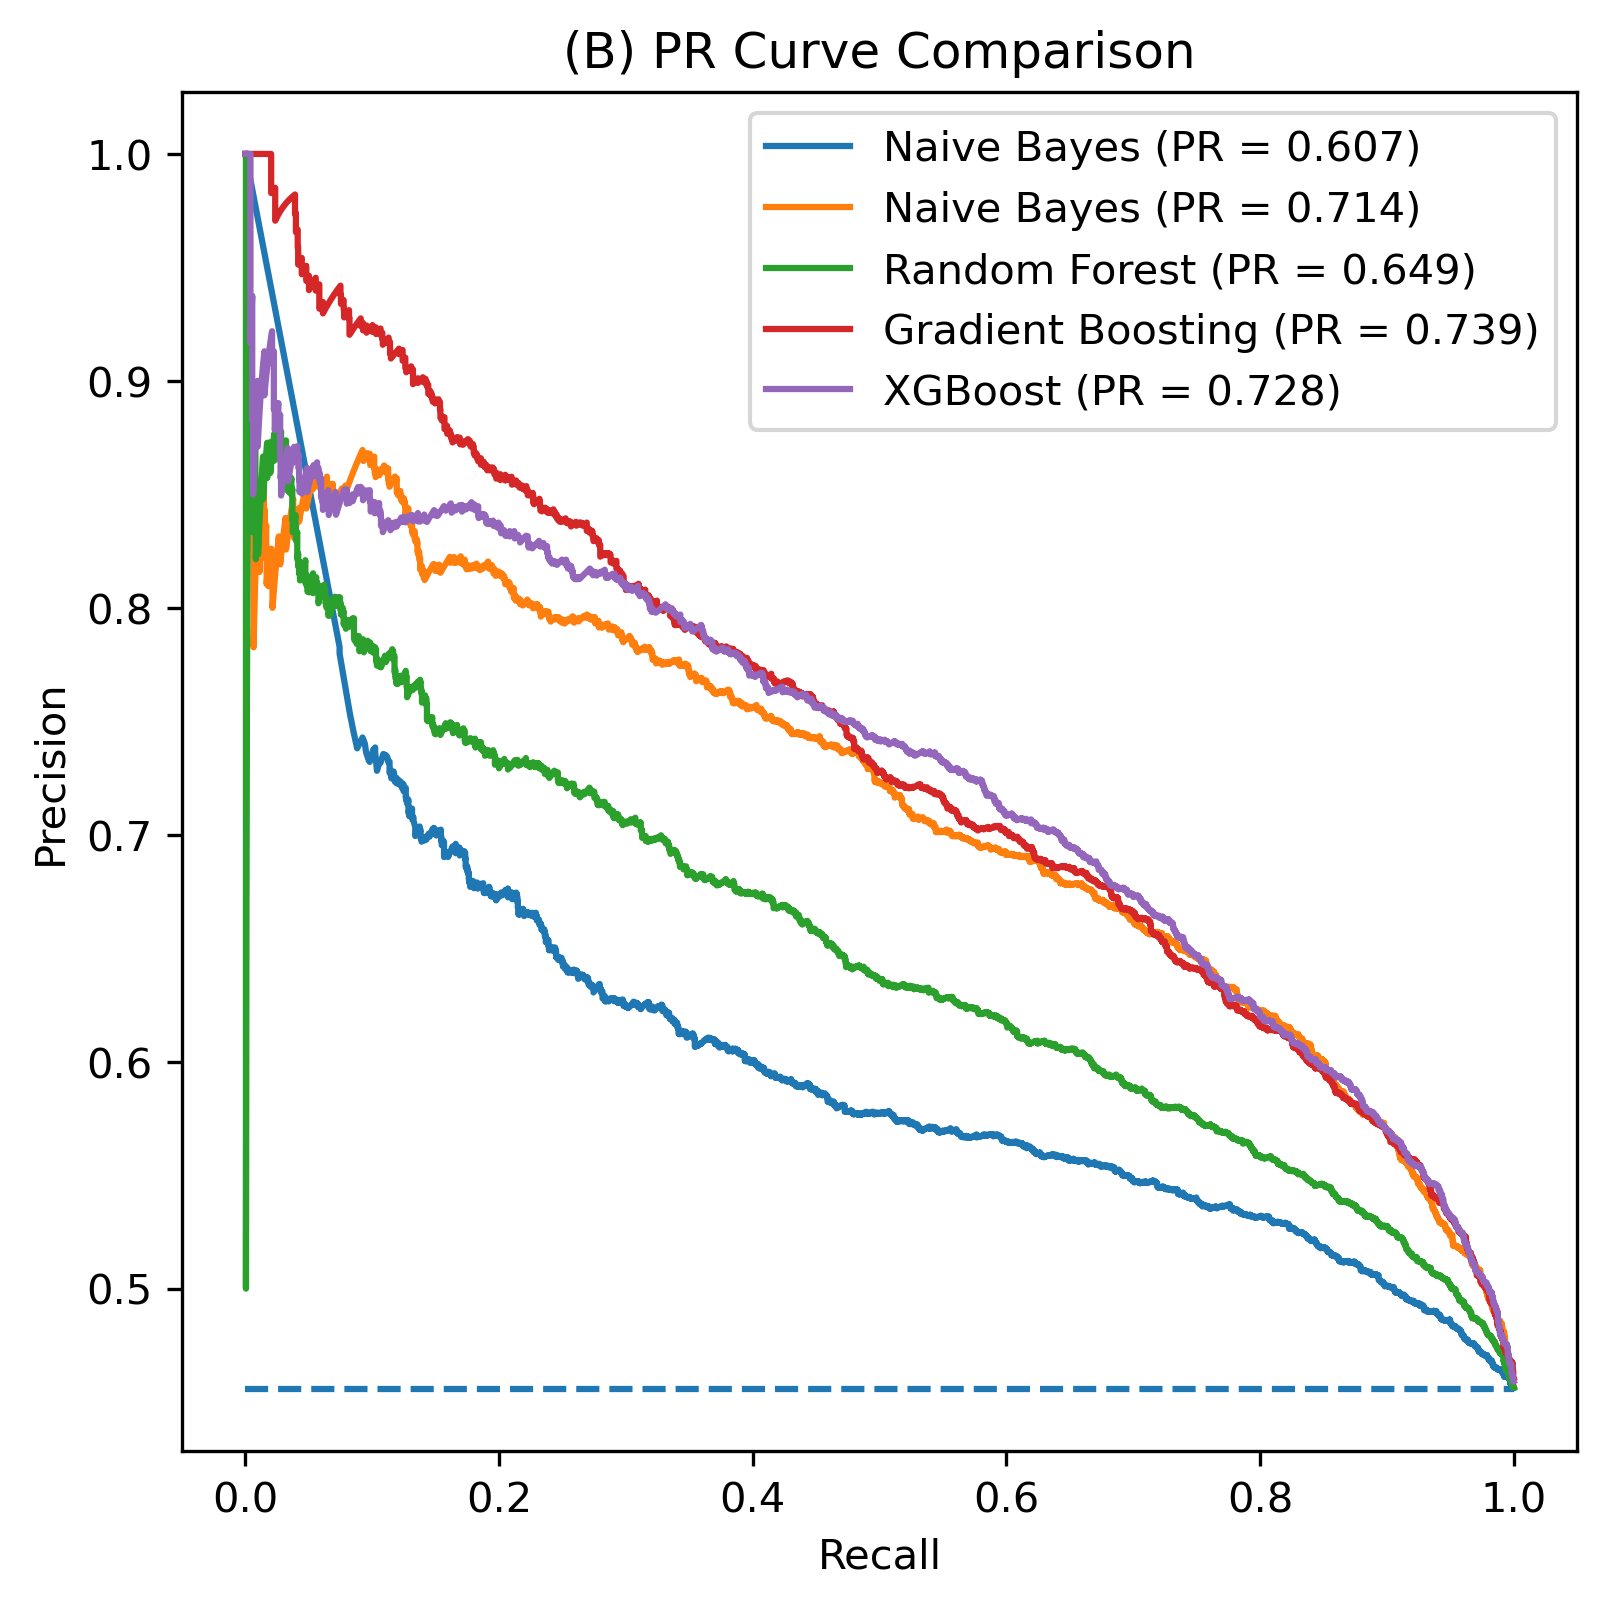

In [14]:
from sklearn.metrics import precision_recall_curve, auc

# PR for Models
precision_nb, recall_nb, _nb = precision_recall_curve(y_test, y_scores_nb)
pr_auc_nb = auc(recall_nb, precision_nb)

precision_lr, recall_lr, _lr = precision_recall_curve(y_test, y_scores_lr)
pr_auc_lr = auc(recall_lr, precision_lr)

precision_rf, recall_rf, _rf = precision_recall_curve(y_test, y_scores_rf)
pr_auc_rf = auc(recall_rf, precision_rf)

precision_gbc, recall_gbc, _gbc = precision_recall_curve(y_test, y_scores_gbc)
pr_auc_gbc = auc(recall_gbc, precision_gbc)

precision_xgb, recall_xgb, _xgb = precision_recall_curve(y_test, y_scores_xgb)
pr_auc_xgb = auc(recall_xgb, precision_xgb)

# Plot comparison
plt.figure(figsize=(6, 6))

plt.plot(recall_nb, precision_nb, label=f'Naive Bayes (PR = {pr_auc_nb:.3f})')
plt.plot(recall_lr, precision_lr, label=f'Naive Bayes (PR = {pr_auc_lr:.3f})')
plt.plot(recall_rf, precision_rf, label=f'Random Forest (PR = {pr_auc_rf:.3f})')
plt.plot(recall_gbc, precision_gbc, label=f'Gradient Boosting (PR = {pr_auc_gbc:.3f})')
plt.plot(recall_xgb, precision_xgb, label=f'XGBoost (PR = {pr_auc_xgb:.3f})')

baseline = sum(y_test.values) / len(y_test.values)
plt.hlines(baseline, 0, 1, linestyles='--')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('(B) PR Curve Comparison')
plt.legend()

plt.show()

/opt/anaconda3/lib/python3.8/site-packages/xgboost/data.py:192: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


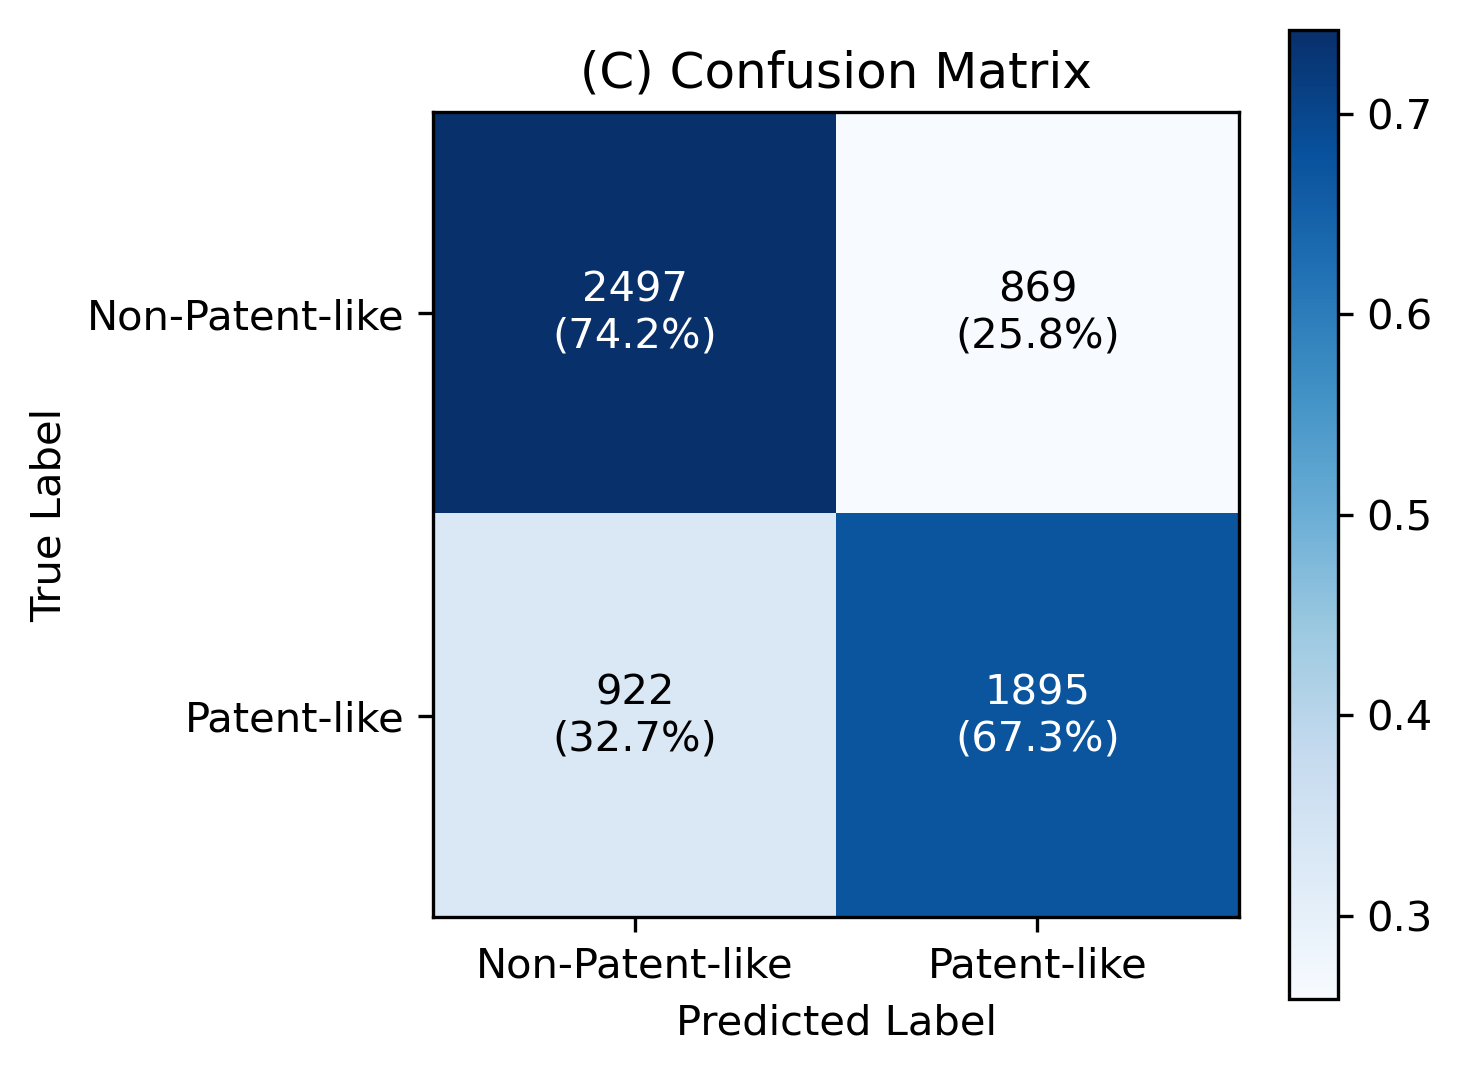

In [12]:
y_pred = xgb_best_model.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Normalize
cm_percent = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(cm_percent, cmap='Blues')

# Add colorbar
cbar = plt.colorbar(im, shrink=0.7)

# Labels
classes = ['Non-Patent-like', 'Patent-like']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)

ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('(C) Confusion Matrix')

# 🔑 Key: adaptive text color
threshold = cm_percent.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm_percent[i, j]
        
        # White text for dark cells, black for light cells
        color = "white" if value > threshold else "black"
        
        ax.text(j, i,
                f"{cm[i, j]}\n({value*100:.1f}%)",
                ha="center", va="center",
                color=color)

plt.tight_layout()
plt.show()

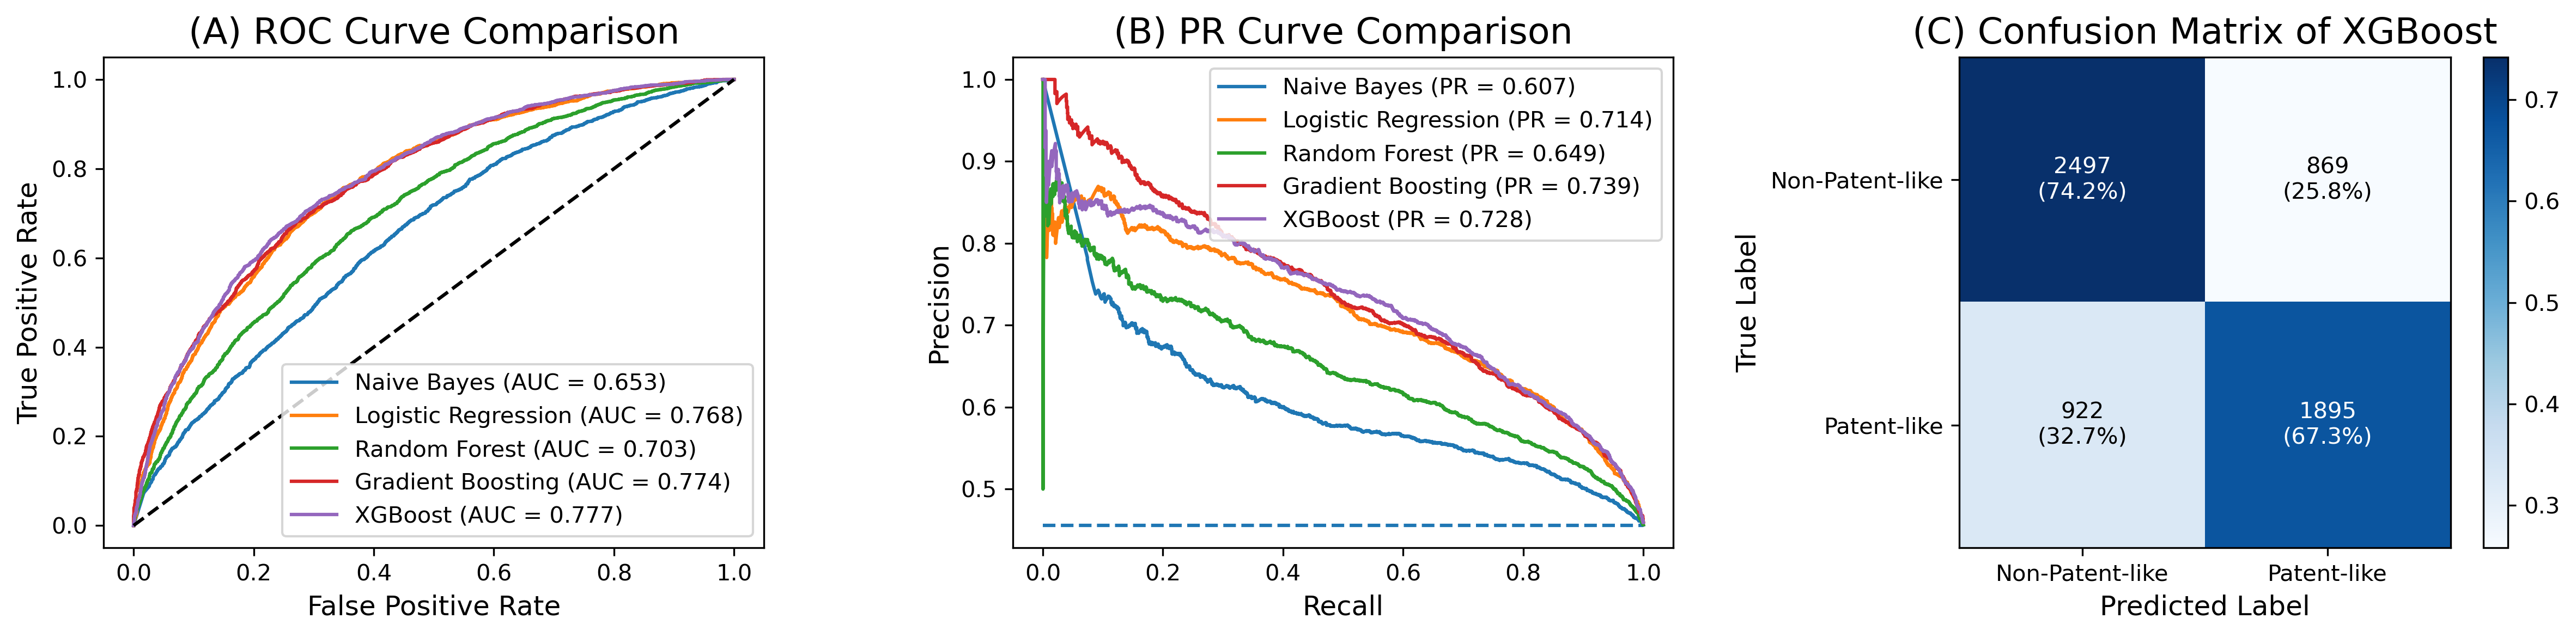

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- (a) ROC Curve ---
axes[0].plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {roc_auc_nb:.3f})')
axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})')
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
axes[0].plot(fpr_gbc, tpr_gbc, label=f'Gradient Boosting (AUC = {roc_auc_gbc:.3f})')
axes[0].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--')

axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('(A) ROC Curve Comparison', fontsize=16)
axes[0].legend(loc='lower right')

# --- (b) PR Curve ---
axes[1].plot(recall_nb, precision_nb, label=f'Naive Bayes (PR = {pr_auc_nb:.3f})')
axes[1].plot(recall_lr, precision_lr, label=f'Logistic Regression (PR = {pr_auc_lr:.3f})')
axes[1].plot(recall_rf, precision_rf, label=f'Random Forest (PR = {pr_auc_rf:.3f})')
axes[1].plot(recall_gbc, precision_gbc, label=f'Gradient Boosting (PR = {pr_auc_gbc:.3f})')
axes[1].plot(recall_xgb, precision_xgb, label=f'XGBoost (PR = {pr_auc_xgb:.3f})')

baseline = sum(y_test.values) / len(y_test.values)
axes[1].hlines(baseline, 0, 1, linestyles='--')

axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('(B) PR Curve Comparison', fontsize=16)
axes[1].legend()

# --- (c) Confusion Matrix ---
im = axes[2].imshow(cm_percent, cmap='Blues')

# # Add colorbar
# cbar = plt.colorbar(im, shrink=0.7)

# Labels
classes = ['Non-Patent-like', 'Patent-like']
axes[2].set_xticks([0, 1])
axes[2].set_yticks([0, 1])
axes[2].set_xticklabels(classes)
axes[2].set_yticklabels(classes)

axes[2].set_xlabel('Predicted Label', fontsize=12)
axes[2].set_ylabel('True Label', fontsize=12)
axes[2].set_title('(C) Confusion Matrix of XGBoost', fontsize=16)

# 🔑 Key: adaptive text color
threshold = cm_percent.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm_percent[i, j]
        
        # White text for dark cells, black for light cells
        color = "white" if value > threshold else "black"
        
        axes[2].text(j, i,
                f"{cm[i, j]}\n({value*100:.1f}%)",
                ha="center", va="center",
                color=color)
        
# for i in range(cm.shape[0]):
#     for j in range(cm.shape[1]):
#         color = "white" if cm_percent[i, j] > 0.5 else "black"
#         axes[2].text(j, i,
#                      f"{cm[i,j]}",
#                      ha="center", va="center", color=color)

fig.colorbar(im, ax=axes[2], shrink=1)

plt.tight_layout()
# plt.savefig("outputFiles/TRI_Figure_2.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.show()


# Figure 4

In [4]:
df_uwa_compot = pd.read_csv('Data/694_UWA_Overlaps_with_compot.csv')

In [5]:
df_uwa_compot.shape

(694, 97)

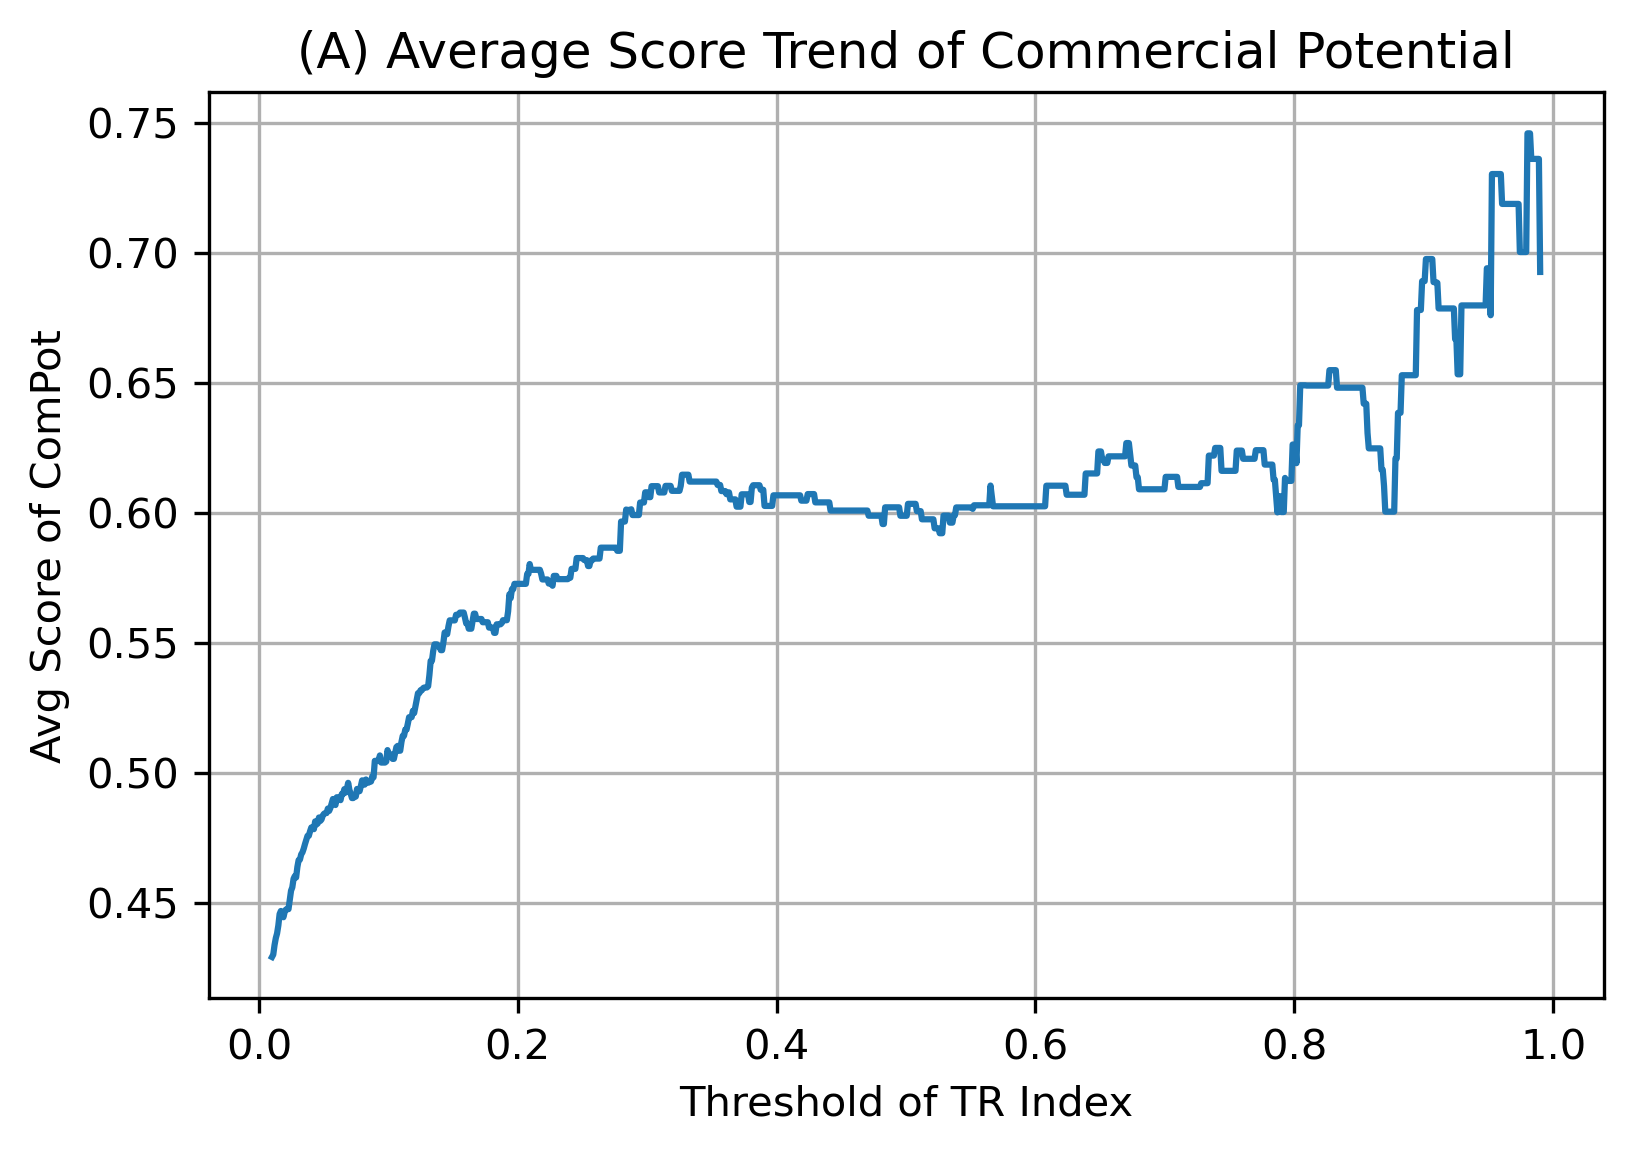

In [6]:
# -----------------------------
# Column names
# -----------------------------
prob_col = "Pred_Prob"
compot_col = "compot"

# -----------------------------
# Basic cleaning
# -----------------------------
df_eval = df_uwa_compot[[prob_col, compot_col]].dropna().copy()

# If probabilities are 0–100, convert:
# df_eval[prob_col] = df_eval[prob_col] / 100.0

# -----------------------------
# Generate 1000 thresholds (1% → 99%)
# -----------------------------
thresholds = np.linspace(0.01, 0.99, 1000)

results = []

for threshold in thresholds:
    # Predict patent based on threshold
    predicted_patent = df_eval[prob_col] >= threshold

    # Count pqrs == 1 among predicted patents
    compot_avg = df_eval.loc[predicted_patent, compot_col].mean()

    # Optional: total predicted patents
    total_predicted = predicted_patent.mean()

    results.append({
        "threshold": threshold,
        "compot_avg": compot_avg,
        "total_avg": total_predicted
    })

results_df_compot = pd.DataFrame(results)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(6, 4))

plt.plot(results_df_compot["threshold"], results_df_compot["compot_avg"], label="compot average")
# plt.plot(results_df["threshold"], results_df["pqrs_1_author_count"], label="all author pqrs count")
# plt.plot(results_df["threshold"], results_df["total_predicted"], linestyle="--", label="Total predicted patents")

plt.xlabel("Threshold of TR Index")
plt.ylabel("Avg Score of ComPot")
plt.title("(A) Average Score Trend of Commercial Potential")
# plt.legend()
plt.grid(True)

plt.show()

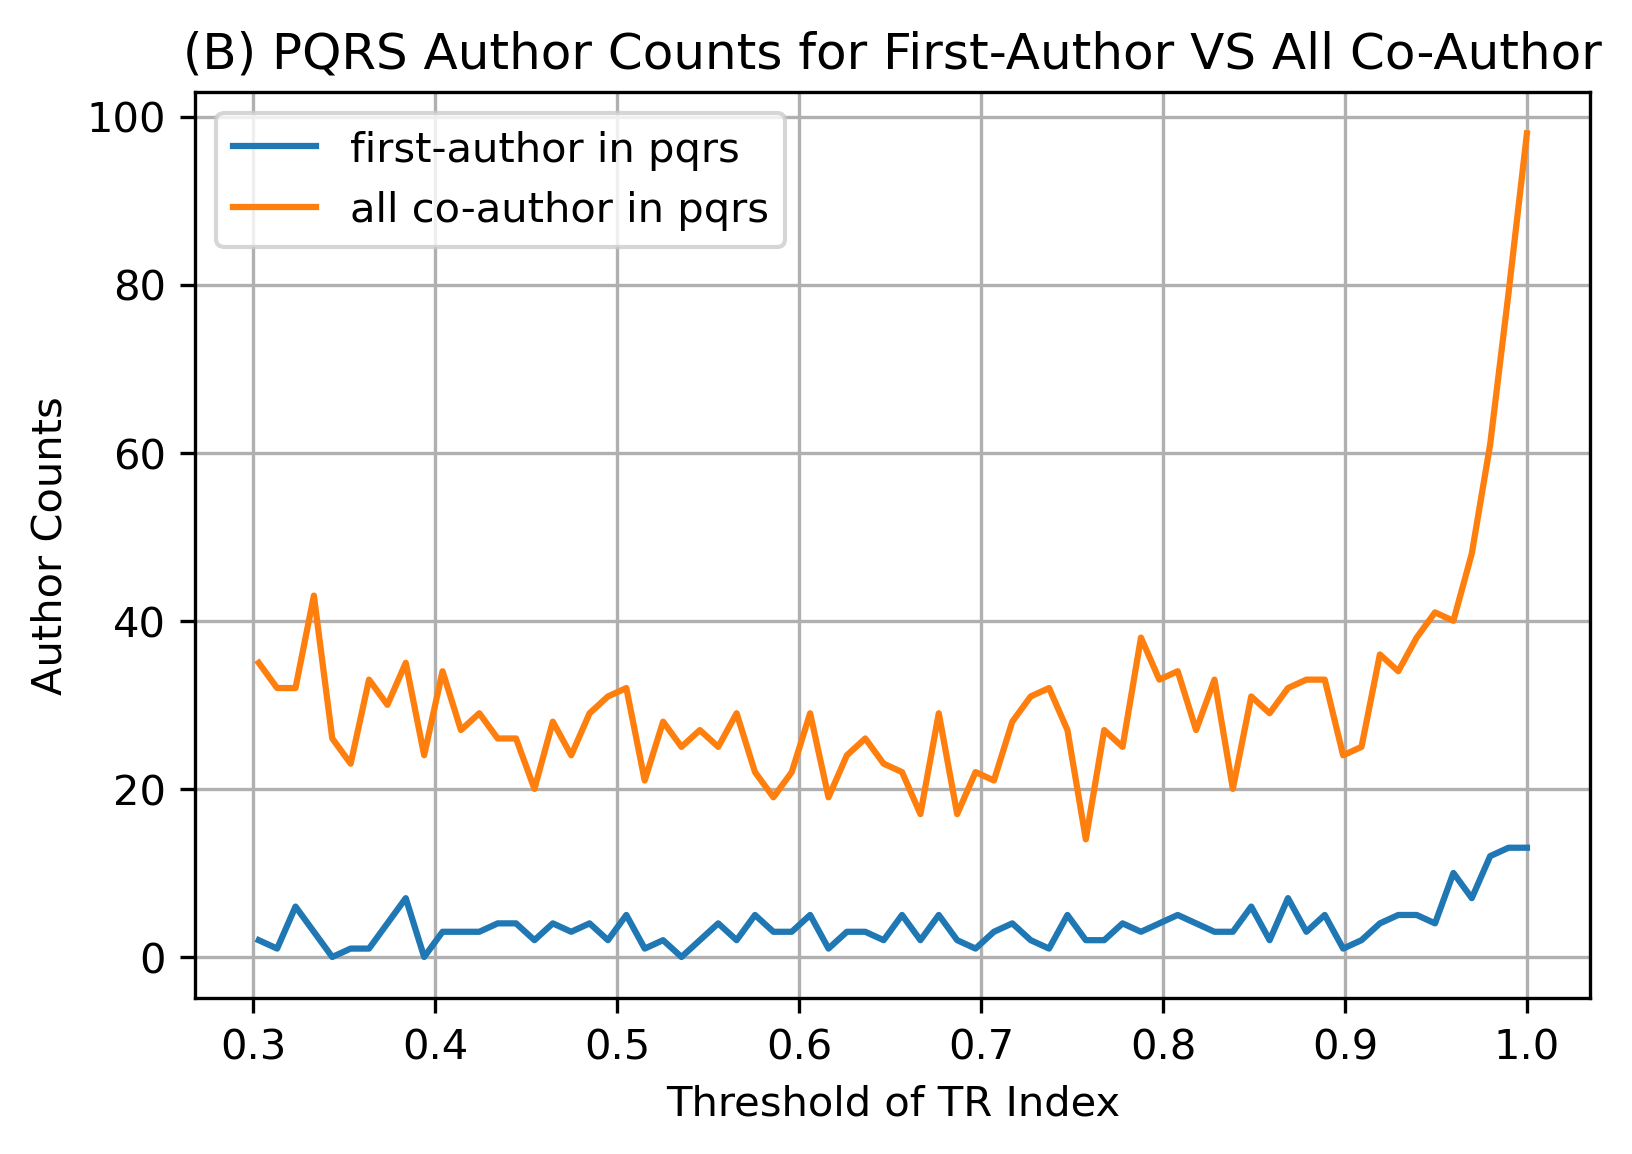

In [7]:
df_uwa_output = pd.read_csv('Data/16k_UWA_results_classifer_v1.csv', low_memory=False)

# -----------------------------
# Column names
# -----------------------------
prob_col = "Pred_Prob"
pqrs_col = "In_pqrs"
pqrs_author_col = "In_pqrs_author"

# -----------------------------
# Basic cleaning
# -----------------------------
df_eval = df_uwa_output[[prob_col, pqrs_col, pqrs_author_col]].dropna().copy()
df_eval[pqrs_col] = df_eval[pqrs_col].astype(int)
df_eval[pqrs_author_col] = df_eval[pqrs_author_col].astype(int)

# If probabilities are 0–100, convert:
# df_eval[prob_col] = df_eval[prob_col] / 100.0

# -----------------------------
# Generate 1000 thresholds (1% → 99%)
# -----------------------------
thresholds = np.linspace(0, 1, 100)

results = []

index = 0
while index < len(thresholds)-1:
    # Predict patent based on threshold
    predicted_patent = ((df_eval[prob_col] >= thresholds[index]) & (df_eval[prob_col] < thresholds[index + 1]))

    # Count pqrs == 1 among predicted patents
    pqrs_1_count = df_eval.loc[predicted_patent, pqrs_col].sum()
    pqrs_1_author_count = df_eval.loc[predicted_patent, pqrs_author_col].sum()

    # Optional: total predicted patents
    total_predicted = predicted_patent.sum()

    results.append({
        "threshold": thresholds[index+1],
        "pqrs_1_count": pqrs_1_count,
        "pqrs_1_author_count": pqrs_1_author_count,
        "total_predicted": total_predicted
    })
    index = index + 1

results_df_pqrs = pd.DataFrame(results)
results_df_pqrs = results_df_pqrs[results_df_pqrs['threshold'] > 0.3]
# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(6, 4))

plt.plot(results_df_pqrs["threshold"], results_df_pqrs["pqrs_1_count"], label="first-author in pqrs")
plt.plot(results_df_pqrs["threshold"], results_df_pqrs["pqrs_1_author_count"], label="all co-author in pqrs")
# plt.plot(results_df["threshold"], results_df["total_predicted"], linestyle="--", label="Total predicted patents")

plt.xlabel("Threshold of TR Index")
plt.ylabel("Author Counts")
plt.title("(B) PQRS Author Counts for First-Author VS All Co-Author")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
df_uwa_top100_paper = pd.read_csv('sourceFiles/UWA Research Translation Readiness Index™ Data - Copy of UWA Research Translation Readiness Index Data.csv')
df_uwa_top100_paper


,Metric,Count,Description,Additional Details
0,Papers with UWA 1st Authors in Startups,2,UWA 1st Authors involved with startups,"clear drum, magic wavelength"
1,Papers with UWA Patent Authors,34,Papers having UWA authors who hold a patent,NaN
2,Pasteur Quadrant Coauthored,51,Papers that have PQRS matched with OpenAlex Id,NaN
3,Company Co-Authored,83,Papers that have company coauthors,NaN
4,Total 100 UWA \nTop TRI™ Papers,100,Top 100 UWA 1st Authored papers,TRI Range 97.8 - 100


In [9]:
df_uwa_top100_paper['Metric'] = ['Papers with UWA\n 1st Authors in Startups',
                                 'Papers with UWA\n Patent Authors',
                                 'Pasteur Quadrant\n Coauthored',
                                 'Company\n Co-Authored',
                                 'Total Top 100\n UWA TRI™ Papers']

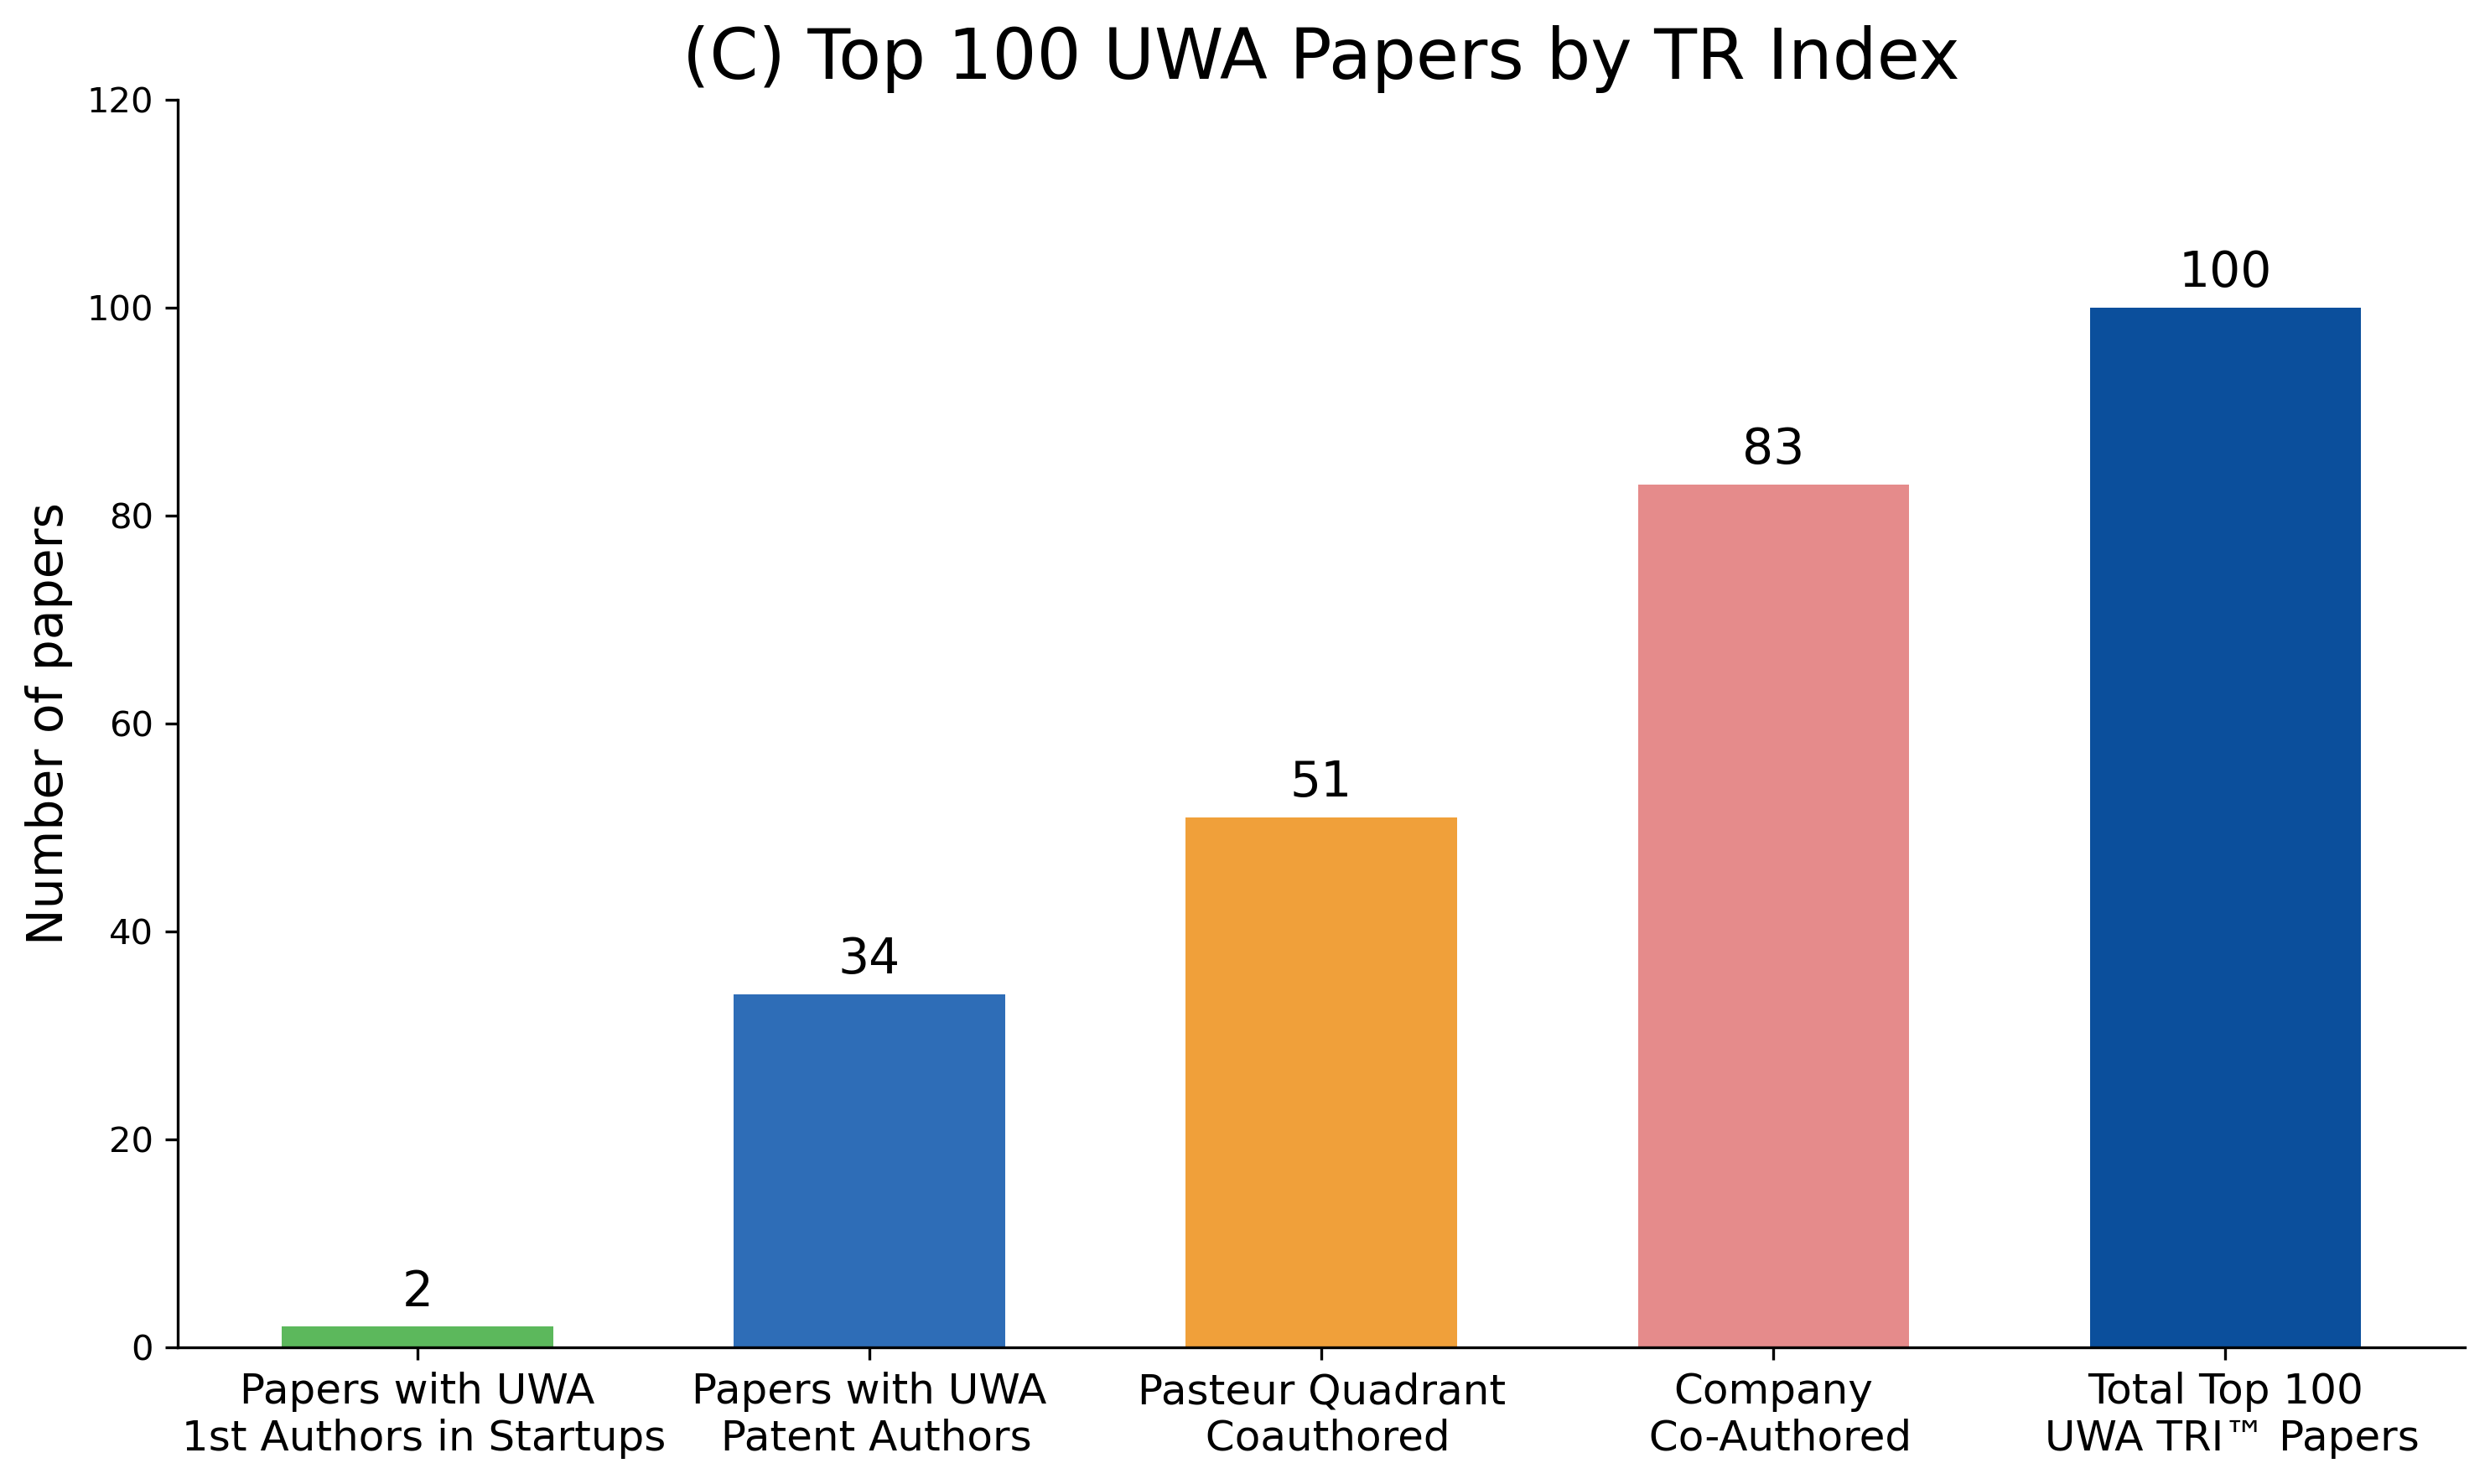

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "#5cb85c",
    "#2e6db7",
    "#f0a03a",
    "#e58b8b",
    "#0b4f9c"
]

bars = ax.bar(
    df_uwa_top100_paper["Metric"],
    df_uwa_top100_paper["Count"],
    color=colors,
    width=0.6
)

# Add numbers above bars
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        f"{int(bar.get_height())}",
        ha="center",
        fontsize=14
    )

ax.set_ylabel("Number of papers", fontsize=14)
ax.set_ylim(0, 120)

plt.xticks(rotation=0, ha="center", fontsize = 12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title('(C) Top 100 UWA Papers by TR Index', fontsize = 20)

plt.tight_layout()
plt.show()

In [17]:
values

array([['In_pqrs_any_author', 55.0, 44.0, 17.0, 34.0],
       ['In_Google_Patent_any_author', 37.0, 18.0, 1.0, 9.0],
       ['In_Company_Coauthored', 9.0, 5.0, 0.0, 5.0]], dtype=object)

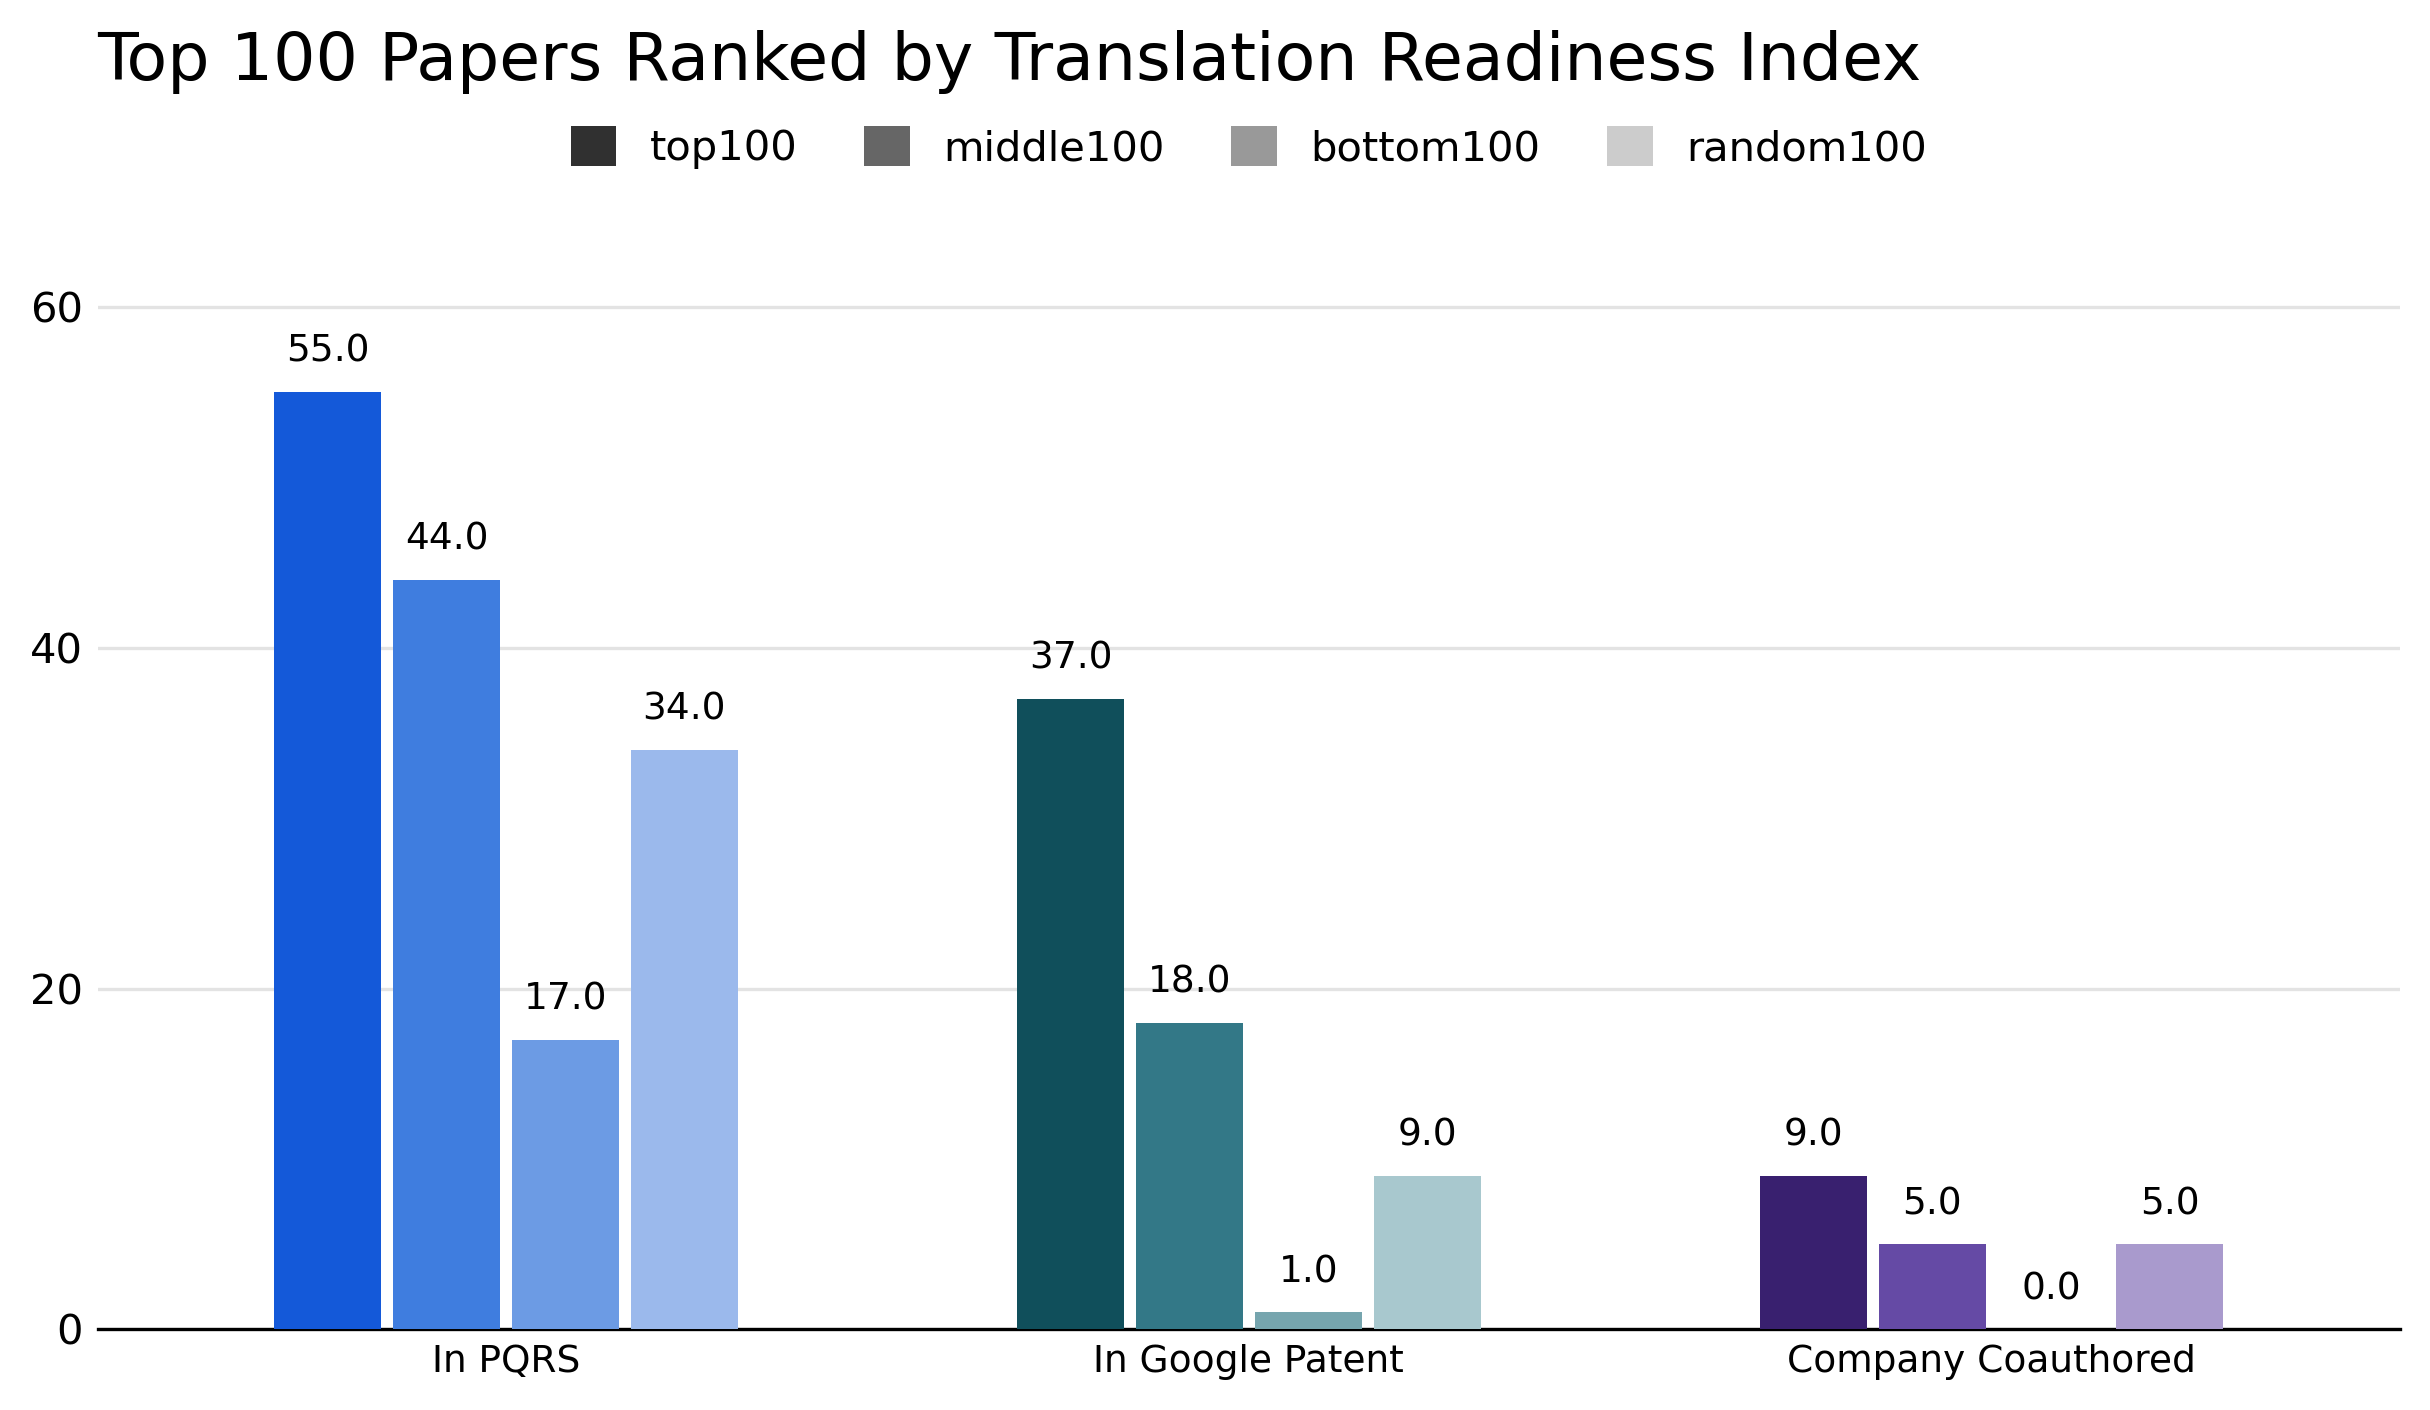

In [19]:
from matplotlib.patches import Patch

# -----------------------------
# Data
# -----------------------------
categories = ["In PQRS", "In Google Patent", "Company Coauthored"]

series = ["top100", "middle100", "bottom100", "random100"]

values = np.array([
    [55, 44, 17, 34],   # In_pqrs_any_author
    [37, 18,  1,  9],    # In_Google_Patent_any_author
    [ 9,  5,  0,  5],   # In_Company_Coauthored
])

df_output_table = pd.read_csv('Data/Top_Mid_Bot_Ran_100_Analysis_Summary_Table.csv')
df_output_table.rename(columns = {'Unnamed: 0':'Group'}, inplace = True)
df_output_table.set_index('Group', inplace = True)
values = df_output_table.values

# Keep the bars colourful.
bar_colors = [
    ["#1459D9", "#3F7DDF", "#6C9BE4", "#9BB9EC"],  # blue shades
    ["#104F5B", "#337887", "#76A5AE", "#A8C8CE"],  # teal shades
    ["#39206F", "#654AA5", "#8D78BE", "#A99ACD"],  # purple shades
]

# Use a grey gradient only for the legend.
legend_greys = ["#303030", "#666666", "#999999", "#CCCCCC"]

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(8.2, 4.8))

x = np.arange(len(categories))
bar_width = 0.16

# Positions of the four bars in each group.
offsets = (np.arange(len(series)) - (len(series) - 1) / 2) * bar_width

for group_index, category in enumerate(categories):
    for series_index in range(len(series)):
        x_position = x[group_index] + offsets[series_index]
        height = values[group_index, series_index]

        ax.bar(
            x_position,
            height,
            width=bar_width * 0.9,
            color=bar_colors[group_index][series_index],
            edgecolor="none",
            zorder=3
        )

        # Value labels
        ax.text(
            x_position,
            height + 1.3,
            str(height),
            ha="center",
            va="bottom",
            fontsize=9
        )

# -----------------------------
# Grey-gradient legend
# -----------------------------
legend_handles = [
    Patch(
        facecolor=grey,
        edgecolor="none",
        label=label
    )
    for grey, label in zip(legend_greys, series)
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),
    ncol=4,
    frameon=False,
    handlelength=1.1,
    handleheight=1.1,
    columnspacing=1.6
)

# -----------------------------
# Formatting
# -----------------------------
ax.set_title(
    "Top 100 Papers Ranked by Translation Readiness Index",
    loc="left",
    fontsize=16,
    color="black",
    pad=34
)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9)

ax.set_ylim(0, 65)
ax.set_yticks([0, 20, 40, 60])

ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.8,
    alpha=0.35,
    zorder=0
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=0)

ax.set_xlim(-0.55, len(categories) - 0.45)

plt.tight_layout()
plt.show()

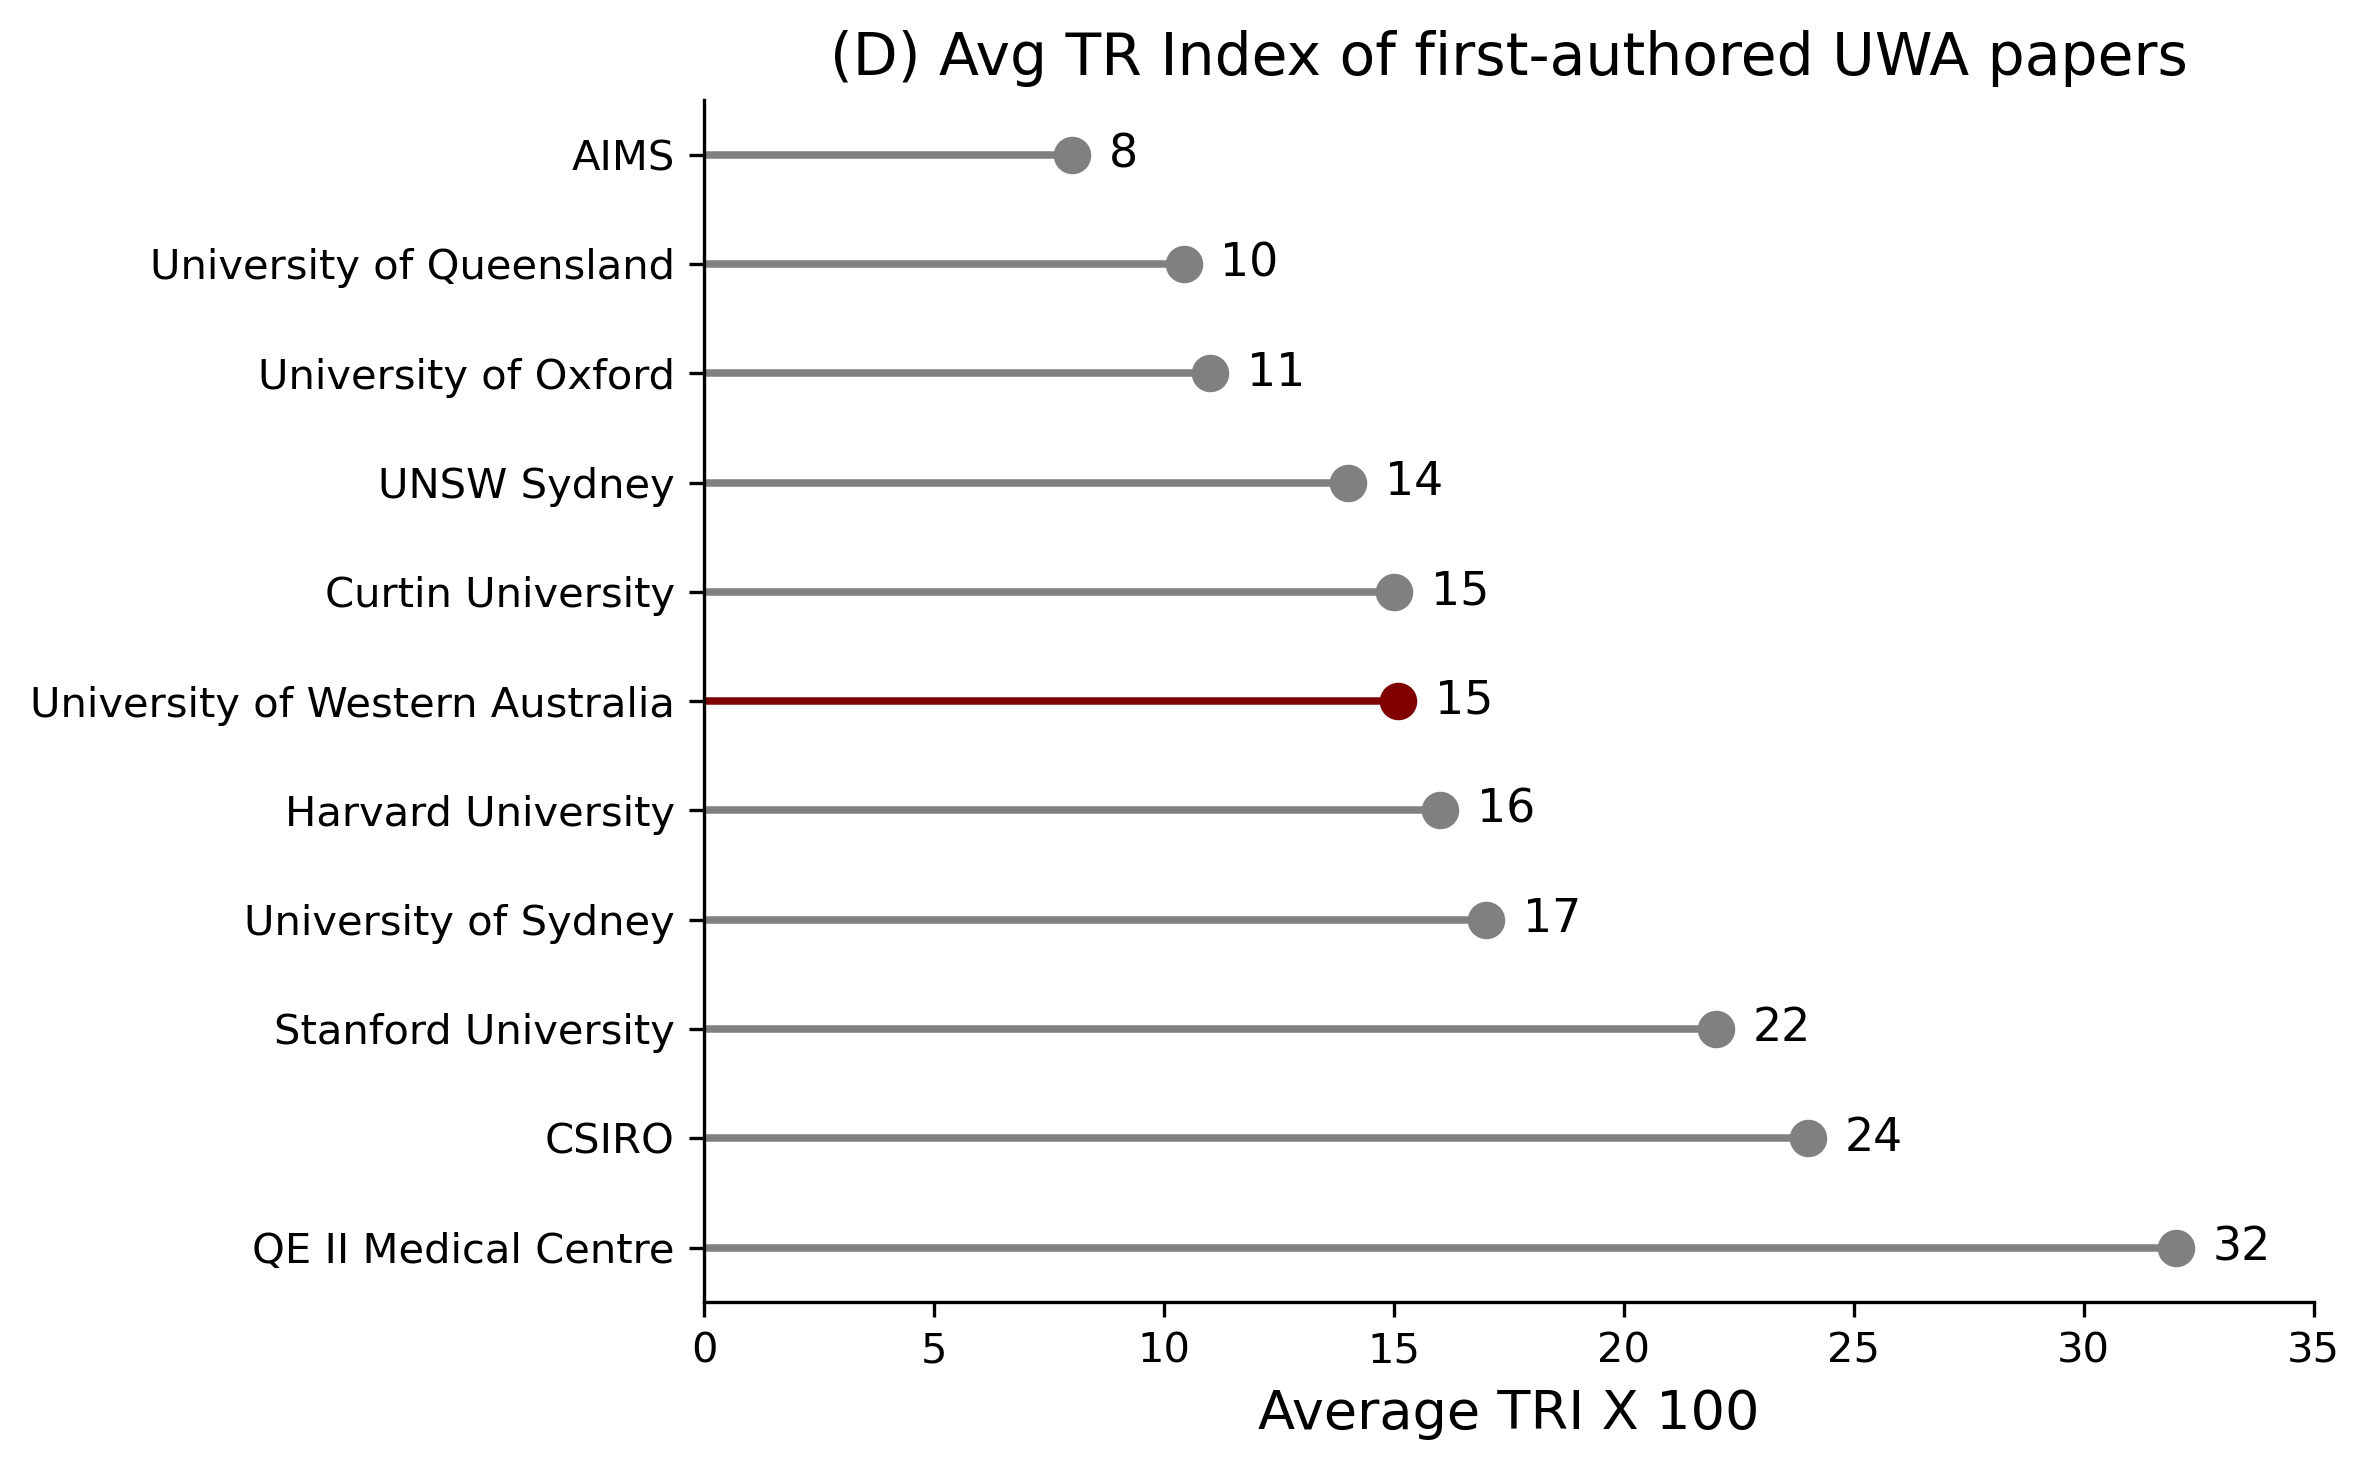

In [21]:
df_uwa_coauthor = pd.read_csv('sourceFiles/TRIs compared - Avg UWA Coauthor TRI by Lead Author Papers.csv')
df_uwa_coauthor

uni_list = ["AIMS", "University of Queensland", "University of Oxford", "UNSW Sydney", "Curtin University", 
            "Harvard University", "University of Sydney", "Stanford University", "CSIRO", "QE II Medical Centre", 
            "University of Western Australia"]
df = df_uwa_coauthor[df_uwa_coauthor['first_author_institutions_name'].isin(uni_list)]
df.columns = ['Institution', 'Avg', 'Counts']

# Convert to percentage-like numbers
plot_df = df.copy()
plot_df["Avg"] = plot_df["Avg"] * 100
plot_df = plot_df.drop_duplicates('Institution', keep = 'last')

# Sort
plot_df = plot_df.sort_values("Avg", ascending = False)

fig, ax = plt.subplots(figsize=(8, 5))

y = np.arange(len(plot_df))

# Highlight top institutions
highlight = ["University of Western Australia"]

for i, row in enumerate(plot_df.itertuples()):

    color = "#800000" if row.Institution in highlight else "grey"

    # horizontal line
    ax.hlines(
        y=i,
        xmin=0,
        xmax=row.Avg,
        color=color,
        linewidth=1.8
    )

    # point
    ax.plot(
        row.Avg,
        i,
        'o',
        color=color,
        markersize=8
    )

    # value label
    ax.text(
        row.Avg + 0.8,
        i,
        f"{row.Avg:.0f}",
        va='center',
        fontsize=11
    )

# axes
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Institution"])

ax.set_xlabel("Average TRI X 100", fontsize=13)

ax.set_title(
    "(D) Avg TR Index of first-authored UWA papers",
    fontsize=14
)

# Nature-style cleanup
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlim(0, 35)

plt.tight_layout()
plt.show()

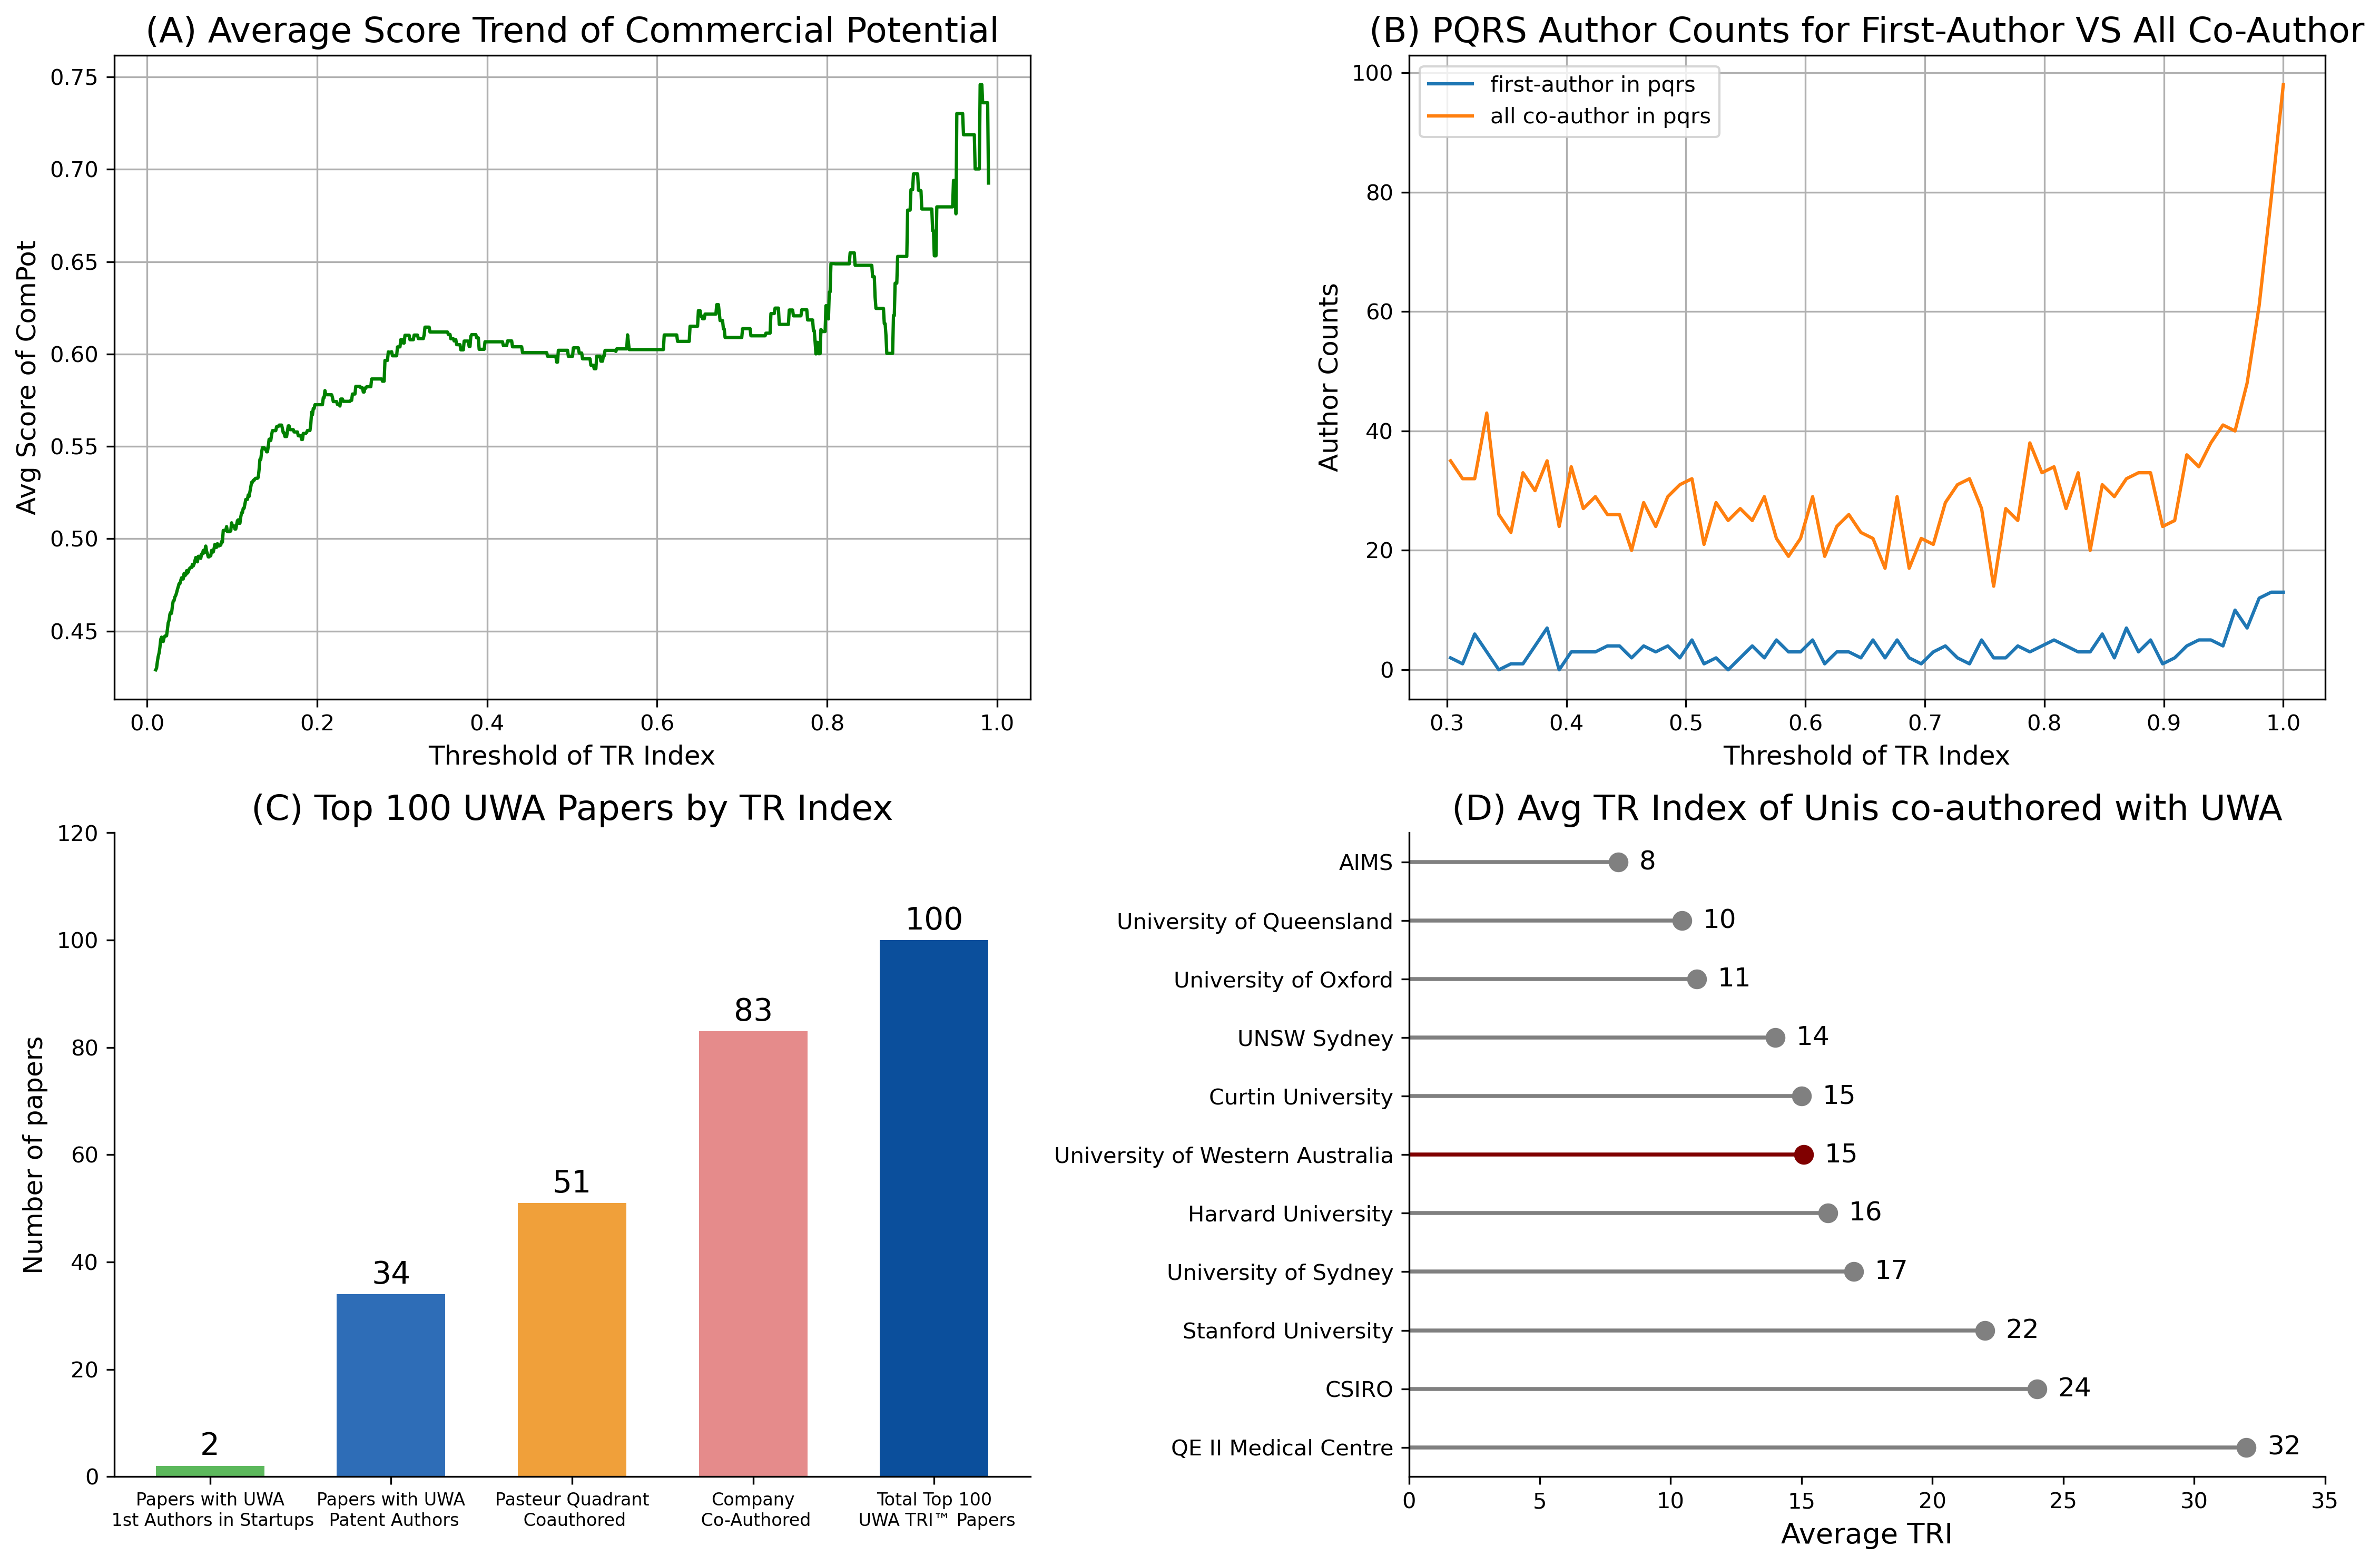

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# --- (a) compot trend ---
axes[0, 0].plot(results_df_compot["threshold"], results_df_compot["compot_avg"], color = 'green')

axes[0, 0].set_xlabel('Threshold of TR Index', fontsize=12)
axes[0, 0].set_ylabel('Avg Score of ComPot', fontsize=12)
axes[0, 0].set_title('(A) Average Score Trend of Commercial Potential', fontsize=16)
axes[0, 0].grid(True)

# --- (b) pqrs trend ---
axes[0, 1].plot(results_df_pqrs["threshold"], results_df_pqrs["pqrs_1_count"], label="first-author in pqrs")
axes[0, 1].plot(results_df_pqrs["threshold"], results_df_pqrs["pqrs_1_author_count"], label="all co-author in pqrs")

axes[0, 1].set_xlabel('Threshold of TR Index', fontsize=12)
axes[0, 1].set_ylabel('Author Counts', fontsize=12)
axes[0, 1].set_title('(B) PQRS Author Counts for First-Author VS All Co-Author', fontsize=16)
axes[0, 1].legend()
axes[0, 1].grid(True)

# --- (c) top 100 UWA paper ---
bars = axes[1, 0].bar(
    df_uwa_top100_paper["Metric"],
    df_uwa_top100_paper["Count"],
    color=colors,
    width=0.6
)

# Add numbers above bars
for bar in bars:
    axes[1, 0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        f"{int(bar.get_height())}",
        ha="center",
        fontsize=14
    )

axes[1, 0].set_ylabel("Number of papers", fontsize=12)
axes[1, 0].set_ylim(0, 120)

# axes[1, 0].set_xticks(fontsize = 12)
axes[1, 0].tick_params(axis='x', labelsize=8)
axes[1, 0].spines["top"].set_visible(False)
axes[1, 0].spines["right"].set_visible(False)
axes[1, 0].set_title('(C) Top 100 UWA Papers by TR Index', fontsize = 16)

# --- (d) avg TR index of UWA co-author paper ---
for i, row in enumerate(plot_df.itertuples()):

    color = "#800000" if row.Institution in highlight else "grey"

    # horizontal line
    axes[1, 1].hlines(
        y=i,
        xmin=0,
        xmax=row.Avg,
        color=color,
        linewidth=1.8
    )

    # point
    axes[1, 1].plot(
        row.Avg,
        i,
        'o',
        color=color,
        markersize=8
    )

    # value label
    axes[1, 1].text(
        row.Avg + 0.8,
        i,
        f"{row.Avg:.0f}",
        va='center',
        fontsize=12
    )

# axes
axes[1, 1].set_yticks(y)
axes[1, 1].set_yticklabels(plot_df["Institution"])

axes[1, 1].set_xlabel("Average TRI", fontsize=13)

axes[1, 1].set_title(
    "(D) Avg TR Index of Unis co-authored with UWA",
    fontsize=16
)

# Nature-style cleanup
axes[1, 1].spines['top'].set_visible(False)
axes[1, 1].spines['right'].set_visible(False)

axes[1, 1].set_xlim(0, 35)

plt.tight_layout()
# plt.savefig("outputFiles/TRI_Figure_3.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.show()


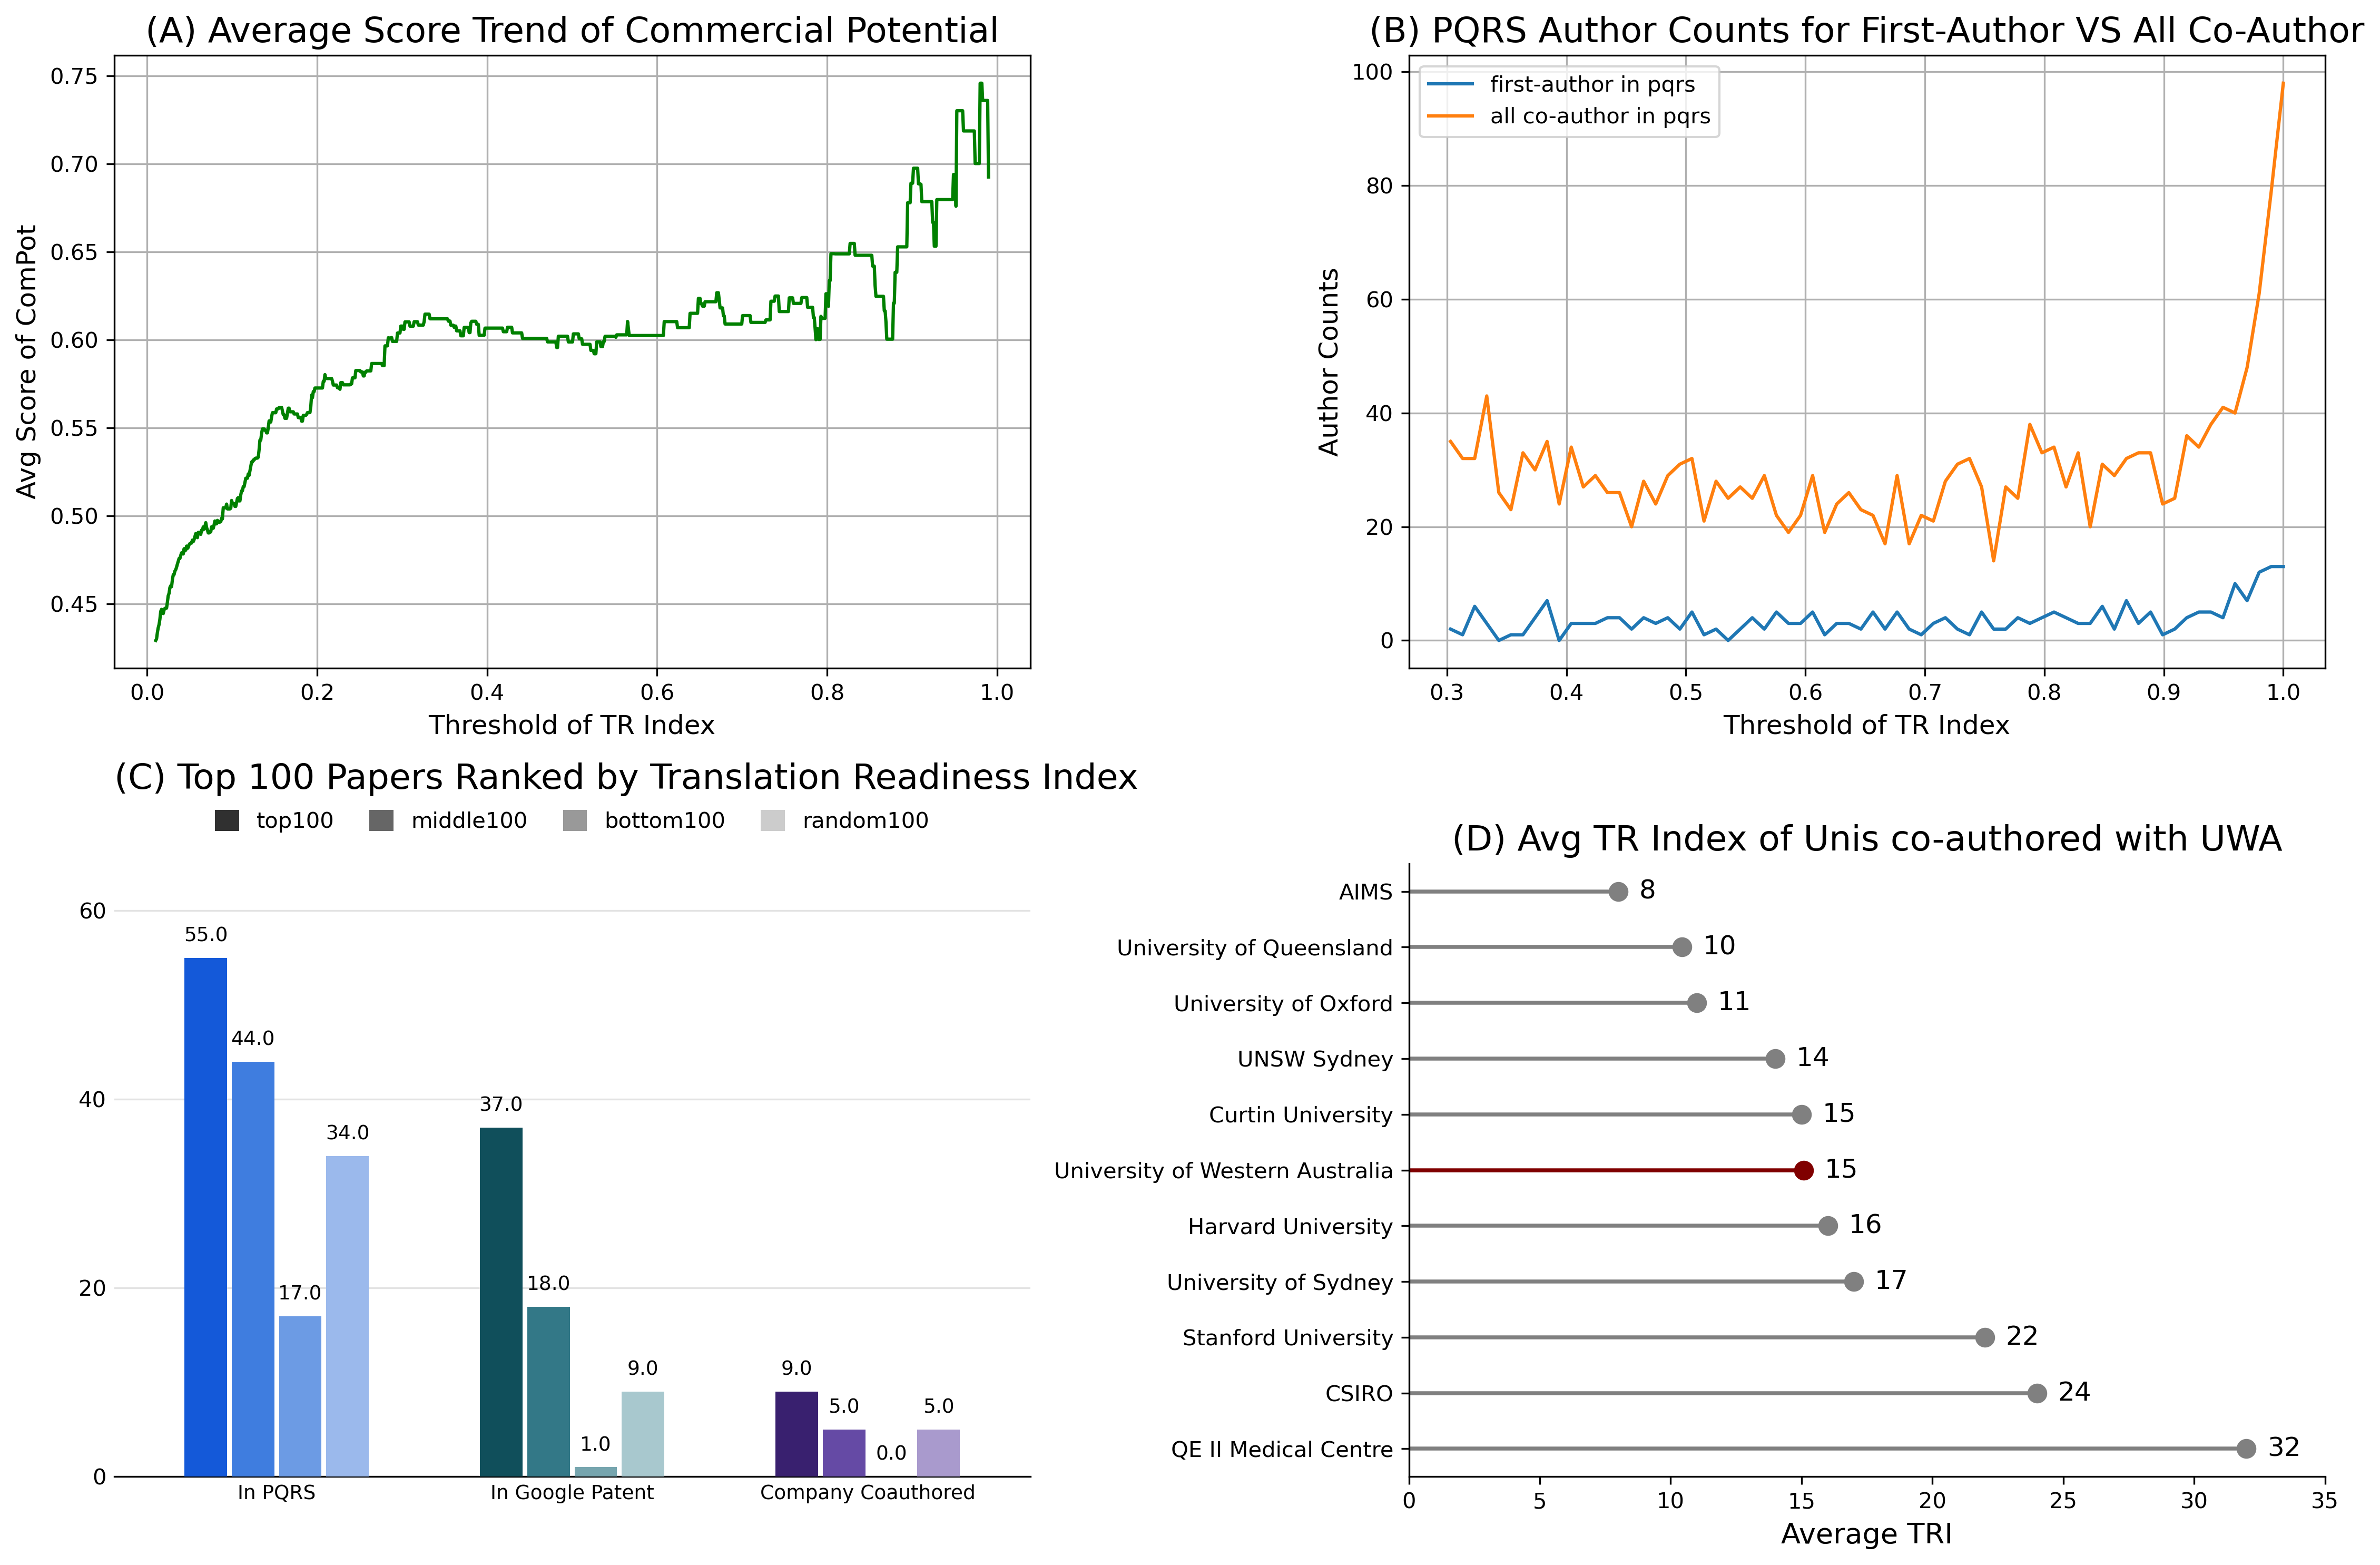

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# =========================================================
# (A) ComPot trend
# =========================================================

axes[0, 0].plot(
    results_df_compot["threshold"],
    results_df_compot["compot_avg"],
    color="green"
)

axes[0, 0].set_xlabel("Threshold of TR Index", fontsize=12)
axes[0, 0].set_ylabel("Avg Score of ComPot", fontsize=12)
axes[0, 0].set_title(
    "(A) Average Score Trend of Commercial Potential",
    fontsize=16
)
axes[0, 0].grid(True)


# =========================================================
# (B) PQRS trend
# =========================================================

axes[0, 1].plot(
    results_df_pqrs["threshold"],
    results_df_pqrs["pqrs_1_count"],
    label="first-author in pqrs"
)

axes[0, 1].plot(
    results_df_pqrs["threshold"],
    results_df_pqrs["pqrs_1_author_count"],
    label="all co-author in pqrs"
)

axes[0, 1].set_xlabel("Threshold of TR Index", fontsize=12)
axes[0, 1].set_ylabel("Author Counts", fontsize=12)
axes[0, 1].set_title(
    "(B) PQRS Author Counts for First-Author VS All Co-Author",
    fontsize=16
)
axes[0, 1].legend()
axes[0, 1].grid(True)


# =========================================================
# (C) Top 100 paper comparison
#     Grouped colourful bars + grey-gradient legend
# =========================================================

ax = axes[1, 0]

x = np.arange(len(categories))
bar_width = 0.16

# Positions of the four bars in each group
offsets = (
    np.arange(len(series)) - (len(series) - 1) / 2
) * bar_width

for group_index, category in enumerate(categories):

    for series_index in range(len(series)):

        x_position = x[group_index] + offsets[series_index]
        height = values[group_index, series_index]

        ax.bar(
            x_position,
            height,
            width=bar_width * 0.9,
            color=bar_colors[group_index][series_index],
            edgecolor="none",
            zorder=3
        )

        # Value labels
        ax.text(
            x_position,
            height + 1.3,
            str(height),
            ha="center",
            va="bottom",
            fontsize=9
        )


# -----------------------------
# Grey-gradient legend
# -----------------------------

legend_handles = [
    Patch(
        facecolor=grey,
        edgecolor="none",
        label=label
    )
    for grey, label in zip(legend_greys, series)
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),
    ncol=4,
    frameon=False,
    handlelength=1.1,
    handleheight=1.1,
    columnspacing=1.6
)


# -----------------------------
# Formatting
# -----------------------------

ax.set_title(
    "(C) Top 100 Papers Ranked by Translation Readiness Index",
    loc="left",
    fontsize=16,
    color="black",
    pad=34
)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9)

ax.set_ylim(0, 65)
ax.set_yticks([0, 20, 40, 60])

ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.8,
    alpha=0.35,
    zorder=0
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=0)

ax.set_xlim(-0.55, len(categories) - 0.45)


# =========================================================
# (D) Average TRI of UWA co-author papers
# =========================================================

for i, row in enumerate(plot_df.itertuples()):

    color = "#800000" if row.Institution in highlight else "grey"

    # Horizontal line
    axes[1, 1].hlines(
        y=i,
        xmin=0,
        xmax=row.Avg,
        color=color,
        linewidth=1.8
    )

    # Point
    axes[1, 1].plot(
        row.Avg,
        i,
        "o",
        color=color,
        markersize=8
    )

    # Value label
    axes[1, 1].text(
        row.Avg + 0.8,
        i,
        f"{row.Avg:.0f}",
        va="center",
        fontsize=12
    )


# Axes
y = np.arange(len(plot_df))

axes[1, 1].set_yticks(y)
axes[1, 1].set_yticklabels(plot_df["Institution"])

axes[1, 1].set_xlabel(
    "Average TRI",
    fontsize=13
)

axes[1, 1].set_title(
    "(D) Avg TR Index of Unis co-authored with UWA",
    fontsize=16
)

# Nature-style cleanup
axes[1, 1].spines["top"].set_visible(False)
axes[1, 1].spines["right"].set_visible(False)

axes[1, 1].set_xlim(0, 35)


# =========================================================
# Layout and save
# =========================================================

plt.tight_layout()

# plt.savefig(
#     "outputFiles/TRI_Figure_4.pdf",
#     format="pdf",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

# Figure 6

In [3]:
df_artu_regression = pd.read_csv('outputFiles/ARTU_Top100_Analysis_Underlying_(OpenAlex).csv')

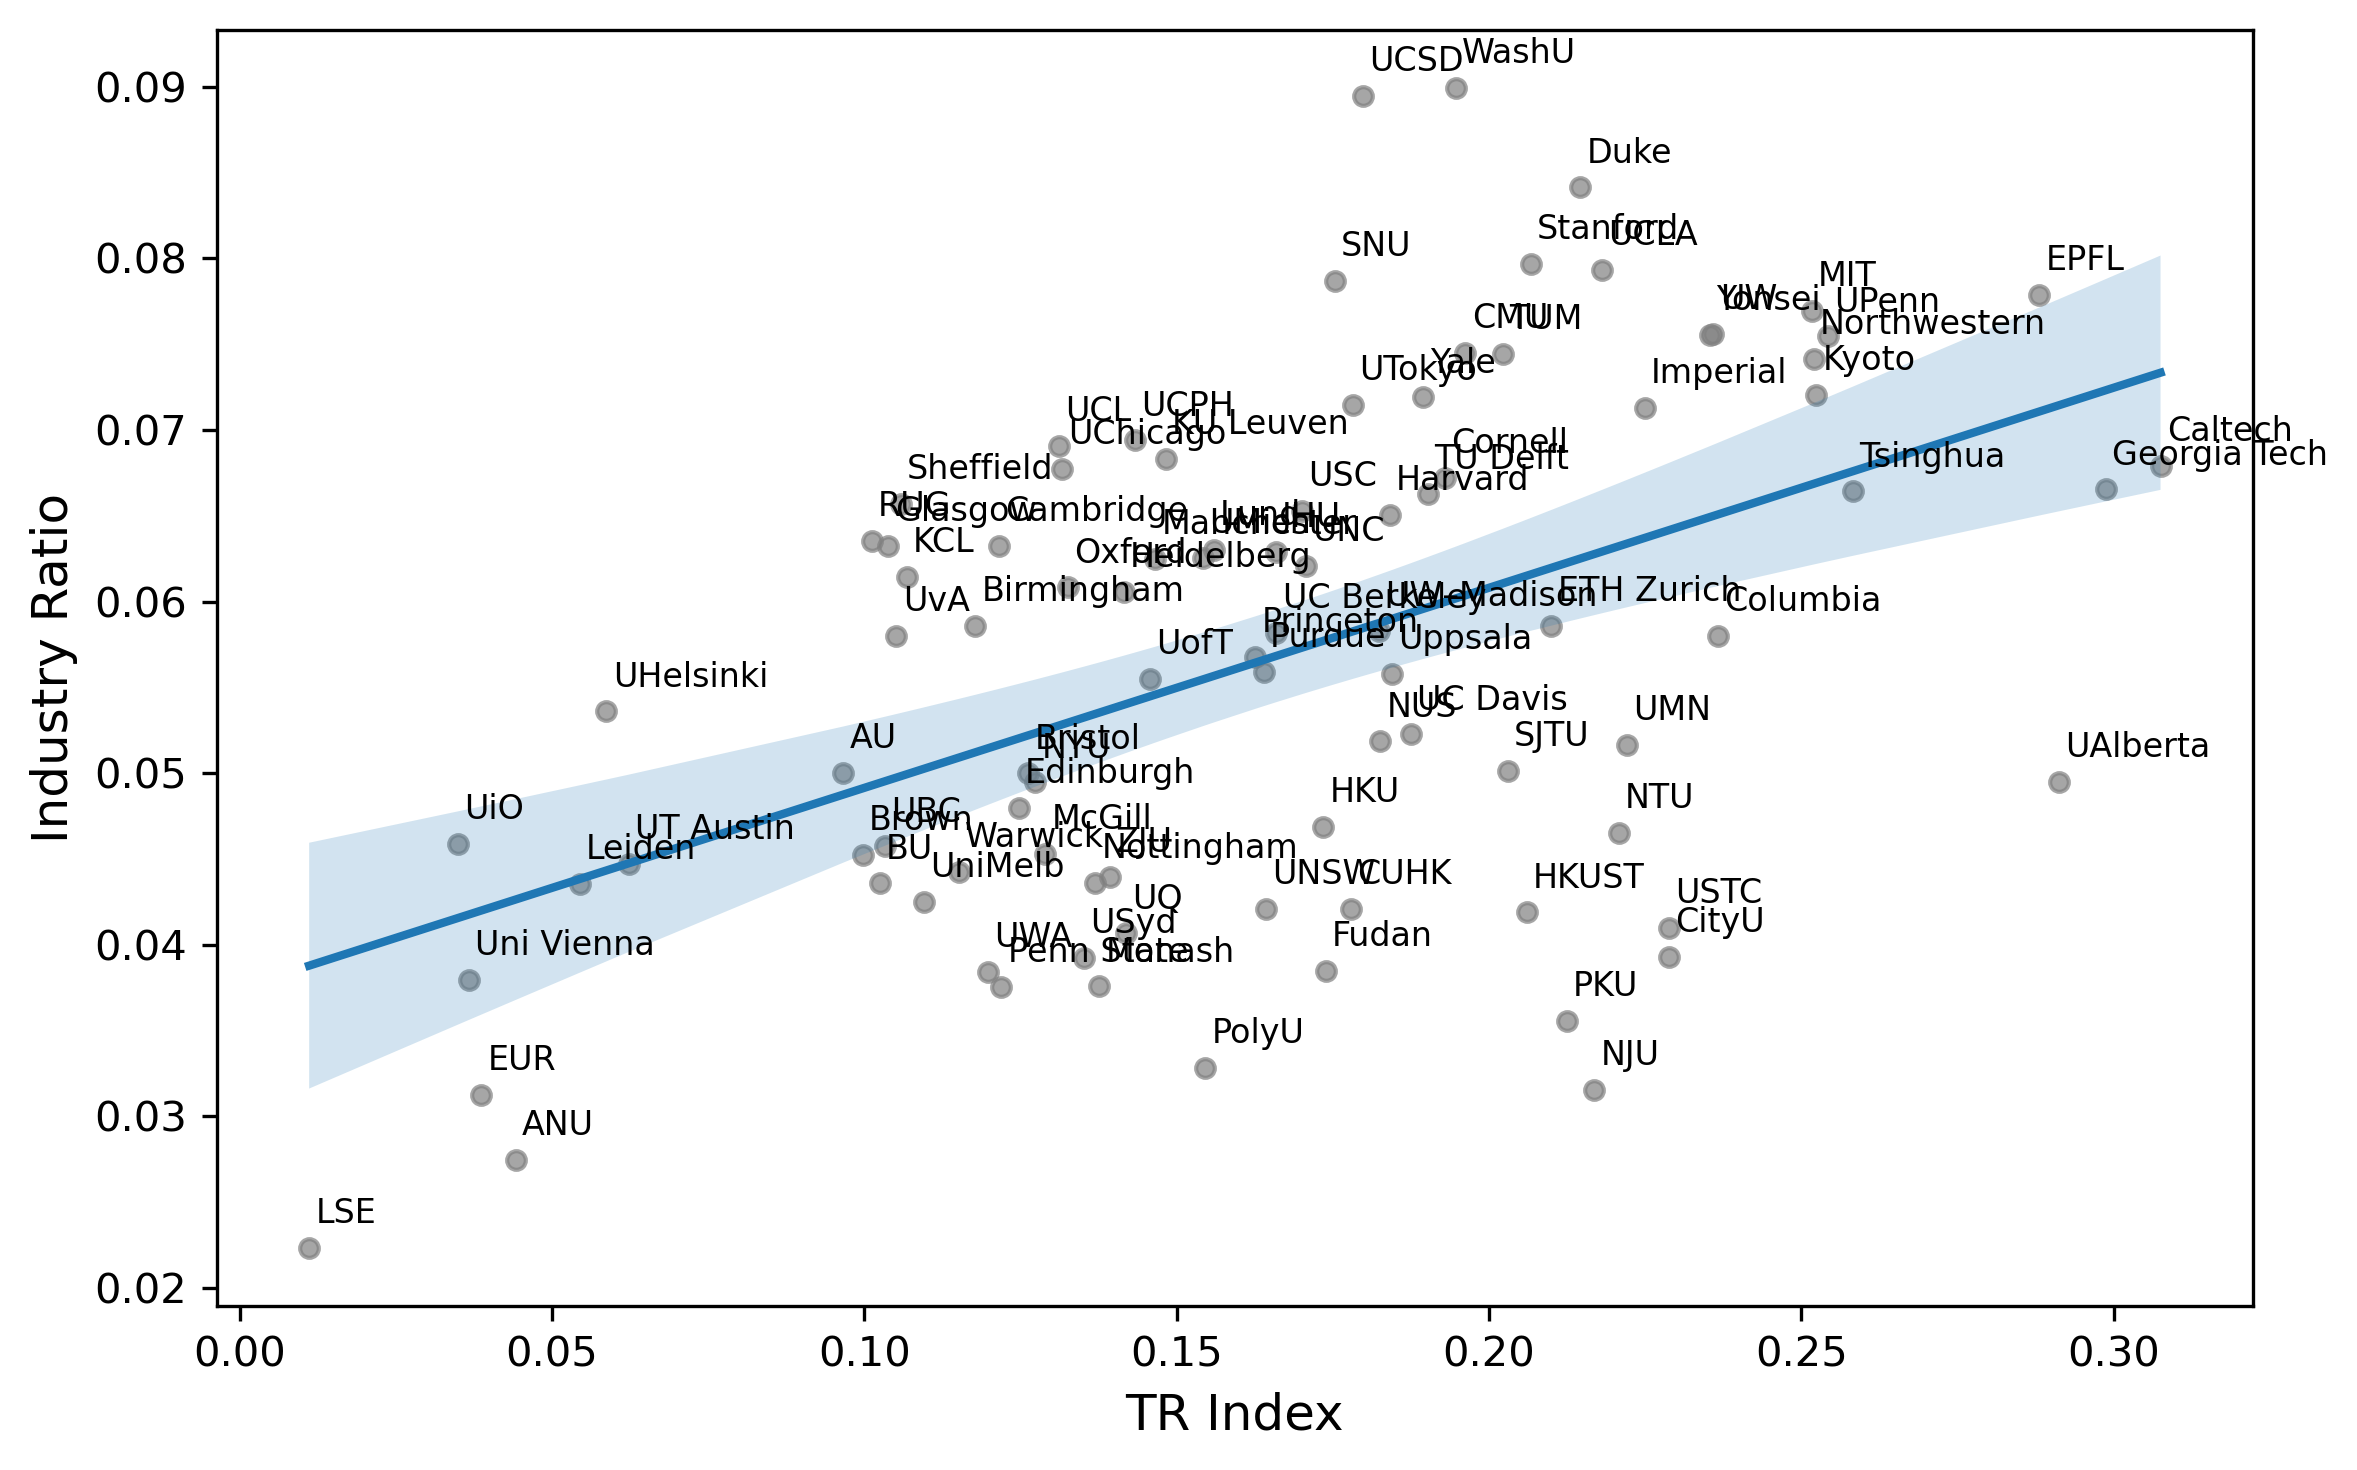

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy import stats

x = df_artu_regression['TRI'].values
y = df_artu_regression['industry'].tolist()

names = df_artu_regression['University'].tolist()

# Fit regression
X = x.reshape(-1, 1)
model = LinearRegression().fit(X, y)
y_pred = model.predict(X)

# Sort for smooth line
sorted_idx = np.argsort(x)
x_sorted = x[sorted_idx]
y_pred_sorted = y_pred[sorted_idx]

# --- Confidence interval ---
n = len(x)
mean_x = np.mean(x)
t_val = stats.t.ppf(0.975, df=n-2)

# Residuals
residuals = y - y_pred
s_err = np.sqrt(np.sum(residuals**2) / (n - 2))

conf = t_val * s_err * np.sqrt(
    1/n + (x_sorted - mean_x)**2 / np.sum((x - mean_x)**2)
)

# --- Plot ---
plt.figure(figsize=(8, 5))

# Grey scatter points
plt.scatter(x, y, color='grey', alpha=0.7, s=20)

# Regression line
plt.plot(x_sorted, y_pred_sorted, linewidth=2)

# Confidence band (error band)
plt.fill_between(x_sorted,
                 y_pred_sorted - conf,
                 y_pred_sorted + conf,
                 alpha=0.2)

# Add labels with connecting lines
for i, name in enumerate(names):
    plt.annotate(name,
                 (x[i], y[i]),
                 xytext=(x[i] + 0.001, y[i] + 0.002),
                 fontsize=8,
                 ha='left',
                 va='center',
#                  arrowprops=dict(
#                      arrowstyle='-',
#                      lw=0.8,
#                      color='black',
#                      shrinkA=0,
#                      shrinkB=0,
#                      connectionstyle="arc3"  # smooth straight line
#                  )
                )

plt.xlabel("TR Index", fontsize=12)
plt.ylabel("Industry Ratio", fontsize=12)
# plt.title("Scatter Plot with Labels", fontsize=13)

plt.tight_layout()
# plt.savefig("ARTU_TRI_Regression.pdf", format="pdf", bbox_inches="tight")
plt.show()

